In [6]:
url='https://finance.yahoo.com/markets/stocks/most-active/'

In [67]:
#1
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
#2
headers = {
    "User-Agent": "Mozilla/5.0", #(Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/153.0.0.0 Safari/537.36",
    #"Accept-Language": "en-US,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8"
}

In [9]:
# step 3
response = requests.get(url,headers=headers)
response

<Response [200]>

In [10]:
soup = BeautifulSoup(response.text)
soup

<!DOCTYPE html>
<html class="desktop neo-green dock-upscale" data-color-scheme="auto" data-color-theme-enabled="true" lang="en-US" theme="auto">
<head>
<meta charset="utf-8"/>
<meta content="guce.yahoo.com" name="oath:guce:consent-host"/>
<link crossorigin="anonymous" href="//s.yimg.com" rel="preconnect"/><link href="//geo.yahoo.com" rel="preconnect"/><link href="//query1.finance.yahoo.com" rel="preconnect"/><link href="//consent.cmp.oath.com" rel="preconnect"/><link href="//cdn.jsdelivr.net" rel="preconnect"/><link as="worker" href="/__rapidworker-1.2.js" rel="preload"/><script>window.finNeoPageStart = Date.now();</script><script>
    (function(){if(!window.YAHOO){window.YAHOO={}};window.YAHOO.context={"consent":{"allowContentPersonalization":true,"allowCrossDeviceMapping":true,"allowFirstPartyAds":true,"allowSellPersonalInfo":true,"canEmbedThirdPartyContent":true,"canSell":true,"consentedVendors":[],"allowAds":true,"allowOnlyLimitedAds":false,"rejectedAllConsent":false,"allowOnlyNonP

In [11]:
page = soup.find_all('td',class_='yf-i6qrb2')
page

[<td class="[&amp;_.symbol]:tw-text-md yf-i6qrb2 lpin shad" data-testid-cell="ticker" style="--_depth: false;"> <div style="display: contents; --background-color:transparent; --hover-bg-color:transparent; --hover-color:var(--enabled-active-emph); --text-color:var(--enabled-active-emph); --hover-focus-color:var(--hovered-emph-same); --text-decoration:underline;"><span class="ticker-wrapper yf-hzimq4"><a aria-label="NIKE, Inc." class="ticker medium [&amp;_.symbol]:tw-text-md hover noPadding yf-hzimq4" data-testid="table-cell-ticker" data-yga='{"yLinkElement":"qte","yLinkElementType":"link","yModuleName":"stocks-datatable","yLinkText":"NKE","yTrafficOrigin":"stocks-datatable default"}' data-ylk="elm:qte;elmt:link;itc:0;sec:stocks-datatable;slk:NKE;source:stocks-datatable%20default" href="/quote/NKE/" title="NIKE, Inc."> <div class="name yf-hzimq4"> <span class="symbol yf-hzimq4">NKE </span> </div> </a> </span></div> </td>,
 <td class="leftAlignHeader companyName yf-i6qrb2" data-testid-cel

In [12]:
for i in page:
    print(i.text)

   NKE     
 NIKE, Inc.  
     
  33.87  -1.28 (-3.64%) 
 -1.28  
 -3.64%  
 142.717M  
      29.461M 
 50.246B  
      16.22 
 -52.41%  
   31.97 72.39  
   NVDA     
 NVIDIA Corporation  
     
  233.95  +3.09 (+1.34%) 
 +3.09  
 +1.34%  
 135.168M  
      122.619M 
 5.649T  
      29.58 
 +26.09%  
   164.27 237.88  
   SPCX     
 Space Exploration Technologies Corp.  
     
  158.96  +10.89 (+7.35%) 
 +10.89  
 +7.35%  
 119.859M  
      92.795M 
 2.094T  
      -- 
 -1.24%  
   104.83 225.64  
   INTC     
 Intel Corporation  
     
  119.33  -0.67 (-0.56%) 
 -0.67  
 -0.56%  
 95.401M  
      107.791M 
 630.791B  
      -- 
 +226.13%  
   32.89 142.35  
   CTVA     
 Vylor, Inc.  
     
  11.92  -0.65 (-5.17%) 
 -0.65  
 -5.17%  
 78.829M  
      6.942M 
 7.953B  
      41.79 
 -81.46%  
   11.84 90.97  
   NU     
 Nu Holdings Ltd.  
     
  13.43  +0.14 (+1.05%) 
 +0.14  
 +1.05%  
 78.03M  
      82.963M 
 64.876B  
      18.30 
 -12.68%  
   11.20 18.98  
   NOK     
 Nokia O

In [13]:
page = soup.find_all('td',class_='yf-i6qrb2')
page

[<td class="[&amp;_.symbol]:tw-text-md yf-i6qrb2 lpin shad" data-testid-cell="ticker" style="--_depth: false;"> <div style="display: contents; --background-color:transparent; --hover-bg-color:transparent; --hover-color:var(--enabled-active-emph); --text-color:var(--enabled-active-emph); --hover-focus-color:var(--hovered-emph-same); --text-decoration:underline;"><span class="ticker-wrapper yf-hzimq4"><a aria-label="NIKE, Inc." class="ticker medium [&amp;_.symbol]:tw-text-md hover noPadding yf-hzimq4" data-testid="table-cell-ticker" data-yga='{"yLinkElement":"qte","yLinkElementType":"link","yModuleName":"stocks-datatable","yLinkText":"NKE","yTrafficOrigin":"stocks-datatable default"}' data-ylk="elm:qte;elmt:link;itc:0;sec:stocks-datatable;slk:NKE;source:stocks-datatable%20default" href="/quote/NKE/" title="NIKE, Inc."> <div class="name yf-hzimq4"> <span class="symbol yf-hzimq4">NKE </span> </div> </a> </span></div> </td>,
 <td class="leftAlignHeader companyName yf-i6qrb2" data-testid-cel

In [14]:
for i in page:
    print(i.text)

   NKE     
 NIKE, Inc.  
     
  33.87  -1.28 (-3.64%) 
 -1.28  
 -3.64%  
 142.717M  
      29.461M 
 50.246B  
      16.22 
 -52.41%  
   31.97 72.39  
   NVDA     
 NVIDIA Corporation  
     
  233.95  +3.09 (+1.34%) 
 +3.09  
 +1.34%  
 135.168M  
      122.619M 
 5.649T  
      29.58 
 +26.09%  
   164.27 237.88  
   SPCX     
 Space Exploration Technologies Corp.  
     
  158.96  +10.89 (+7.35%) 
 +10.89  
 +7.35%  
 119.859M  
      92.795M 
 2.094T  
      -- 
 -1.24%  
   104.83 225.64  
   INTC     
 Intel Corporation  
     
  119.33  -0.67 (-0.56%) 
 -0.67  
 -0.56%  
 95.401M  
      107.791M 
 630.791B  
      -- 
 +226.13%  
   32.89 142.35  
   CTVA     
 Vylor, Inc.  
     
  11.92  -0.65 (-5.17%) 
 -0.65  
 -5.17%  
 78.829M  
      6.942M 
 7.953B  
      41.79 
 -81.46%  
   11.84 90.97  
   NU     
 Nu Holdings Ltd.  
     
  13.43  +0.14 (+1.05%) 
 +0.14  
 +1.05%  
 78.03M  
      82.963M 
 64.876B  
      18.30 
 -12.68%  
   11.20 18.98  
   NOK     
 Nokia O

In [15]:
len(page)

300

In [16]:
len(soup.find_all('td',class_='[&_.symbol]:tw-text-md yf-i6qrb2 lpin shad'))

25

In [17]:
stock_symbols = []

#page = soup.find_all("td", attrs={"data-testid-cell": "ticker"})

for item in page:
    text = str(item)

    symbol = re.findall(r'class="symbol[^"]*">\s*([A-Z]+)', text)

    if symbol:
        stock_symbols.append(symbol[0])

print(stock_symbols)
print("Total symbols:", len(stock_symbols))

['NKE', 'NVDA', 'SPCX', 'INTC', 'CTVA', 'NU', 'NOK', 'AAL', 'GRAB', 'RIVN', 'WBD', 'TSLA', 'SOFI', 'F', 'BBD', 'ITUB', 'SMCI', 'VALE', 'STLA', 'ONDS', 'MARA', 'IREN', 'PCG', 'AGNC', 'RKT']
Total symbols: 25


In [41]:
page = soup.find_all(
    "td",
    attrs={"data-testid-cell": "ticker"}
)

print("Ticker cells:", len(page))
company_names = []

for item in page:
    link = item.find("a")

    if link:
        company_names.append(link.get("aria-label"))

print(company_names)
print("Total names:", len(company_names))

Ticker cells: 25
['NIKE, Inc.', 'NVIDIA Corporation', 'Space Exploration Technologies Corp.', 'Intel Corporation', 'Vylor, Inc.', 'Nu Holdings Ltd.', 'Nokia Oyj', 'American Airlines Group Inc.', 'Grab Holdings Limited', 'Rivian Automotive, Inc.', 'Warner Bros. Discovery, Inc.', 'Tesla, Inc.', 'SoFi Technologies, Inc.', 'Ford Motor Company', 'Banco Bradesco S.A.', 'Itaú Unibanco Holding S.A.', 'Super Micro Computer, Inc.', 'Vale S.A.', 'Stellantis N.V.', 'Ondas Inc.', 'MARA Holdings, Inc.', 'IREN Limited', 'PG&E Corporation', 'AGNC Investment Corp.', 'Rocket Companies, Inc.']
Total names: 25


In [19]:
print(type(page))
print(len(page))
print(page[0])

<class 'bs4.element.ResultSet'>
300
<td class="[&amp;_.symbol]:tw-text-md yf-i6qrb2 lpin shad" data-testid-cell="ticker" style="--_depth: false;"> <div style="display: contents; --background-color:transparent; --hover-bg-color:transparent; --hover-color:var(--enabled-active-emph); --text-color:var(--enabled-active-emph); --hover-focus-color:var(--hovered-emph-same); --text-decoration:underline;"><span class="ticker-wrapper yf-hzimq4"><a aria-label="NIKE, Inc." class="ticker medium [&amp;_.symbol]:tw-text-md hover noPadding yf-hzimq4" data-testid="table-cell-ticker" data-yga='{"yLinkElement":"qte","yLinkElementType":"link","yModuleName":"stocks-datatable","yLinkText":"NKE","yTrafficOrigin":"stocks-datatable default"}' data-ylk="elm:qte;elmt:link;itc:0;sec:stocks-datatable;slk:NKE;source:stocks-datatable%20default" href="/quote/NKE/" title="NIKE, Inc."> <div class="name yf-hzimq4"> <span class="symbol yf-hzimq4">NKE </span> </div> </a> </span></div> </td>


In [21]:
prices = soup.find_all("td", attrs={"data-testid-cell": "price"})

print(len(prices))

0


In [22]:
print(page[0].parent)

<tr class="row yf-i6qrb2" data-testid="data-table-v2-row" data-testid-row="0"> <td class="[&amp;_.symbol]:tw-text-md yf-i6qrb2 lpin shad" data-testid-cell="ticker" style="--_depth: false;"> <div style="display: contents; --background-color:transparent; --hover-bg-color:transparent; --hover-color:var(--enabled-active-emph); --text-color:var(--enabled-active-emph); --hover-focus-color:var(--hovered-emph-same); --text-decoration:underline;"><span class="ticker-wrapper yf-hzimq4"><a aria-label="NIKE, Inc." class="ticker medium [&amp;_.symbol]:tw-text-md hover noPadding yf-hzimq4" data-testid="table-cell-ticker" data-yga='{"yLinkElement":"qte","yLinkElementType":"link","yModuleName":"stocks-datatable","yLinkText":"NKE","yTrafficOrigin":"stocks-datatable default"}' data-ylk="elm:qte;elmt:link;itc:0;sec:stocks-datatable;slk:NKE;source:stocks-datatable%20default" href="/quote/NKE/" title="NIKE, Inc."> <div class="name yf-hzimq4"> <span class="symbol yf-hzimq4">NKE </span> </div> </a> </span></

In [23]:
prices = soup.find_all(
    "td",
    attrs={"data-testid-cell": "intradayprice"}
)
stock_prices = []
for item in prices:
    price = item.find("span").get_text(strip=True)
    stock_prices.append(price)

print(stock_prices)
print("Total prices:", len(stock_prices))

['33.87', '233.95', '158.96', '119.33', '11.92', '13.43', '10.60', '12.94', '3.08', '14.30', '30.94', '370.59', '15.77', '12.10', '3.65', '8.59', '43.69', '13.76', '4.40', '7.24', '11.23', '41.76', '12.32', '8.79', '11.70']
Total prices: 25


In [24]:
changes = soup.find_all(
    "td",
    attrs={"data-testid-cell": "intradaypricechange"}
)

In [25]:
stock_changes = []

for item in changes:
    change = item.find("span").get_text(strip=True)
    stock_changes.append(change)

print(stock_changes)

['-1.28', '+3.09', '+10.89', '-0.67', '-0.65', '+0.14', '+0.23', '-0.19', '-0.04', '-0.46', '-0.01', '+16.48', '-0.07', '-0.17', '+0.14', '+0.14', '+1.77', '+0.31', '-0.29', '+0.12', '+0.02', '+1.11', '+0.15', '-0.16', '-0.27']


In [26]:
change_percent = soup.find_all(
    "td",
    attrs={"data-testid-cell": "percentchange"}
)

stock_change_percent = []

for item in change_percent:
    value = item.find("span").get_text(strip=True)
    stock_change_percent.append(value)

print(stock_change_percent)

['-3.64%', '+1.34%', '+7.35%', '-0.56%', '-5.17%', '+1.05%', '+2.22%', '-1.45%', '-1.28%', '-3.12%', '-0.03%', '+4.65%', '-0.44%', '-1.39%', '+3.99%', '+1.70%', '+4.22%', '+2.30%', '-6.18%', '+1.69%', '+0.18%', '+2.73%', '+1.23%', '-1.79%', '-2.26%']


In [27]:
volumes = soup.find_all(
    "td",
    attrs={"data-testid-cell": "dayvolume"}
)

stock_volumes = []

for item in volumes:
    volume = item.find("span").get_text(strip=True)
    stock_volumes.append(volume)

print(stock_volumes)

['142.717M', '135.168M', '119.859M', '95.401M', '78.829M', '78.03M', '75.816M', '73.233M', '64.559M', '60.862M', '59.656M', '55.33M', '49.554M', '49.154M', '48.378M', '44.952M', '44.497M', '43.093M', '42.883M', '42.798M', '42.275M', '41.744M', '41.517M', '39.793M', '39.134M']


In [28]:
avg_vol = soup.find_all(
    "td",
    attrs={"data-testid-cell": "avgdailyvol3m"}
)

stock_avg_vol = []

for item in avg_vol:
    value = item.get_text(strip=True)
    stock_avg_vol.append(value)

print(stock_avg_vol)

['29.461M', '122.619M', '92.795M', '107.791M', '6.942M', '82.963M', '83.736M', '81.233M', '53.398M', '27.801M', '30.499M', '38.16M', '58.677M', '48.11M', '29.902M', '22.163M', '44.624M', '26.317M', '22.825M', '80.059M', '47.142M', '42.659M', '35.867M', '25.468M', '30.302M']


In [29]:
market_cap = soup.find_all(
    "td",
    attrs={"data-testid-cell": "intradaymarketcap"}
)

stock_market_cap = []

for item in market_cap:
    value = item.get_text(strip=True)
    stock_market_cap.append(value)

print(stock_market_cap)

['50.246B', '5.649T', '2.094T', '630.791B', '7.953B', '64.876B', '59.346B', '8.566B', '12.601B', '20.704B', '77.571B', '1.464T', '20.368B', '48.25B', '38.65B', '94.678B', '28.262B', '58.559B', '12.764B', '4.216B', '4.338B', '16.456B', '36.989B', '10.42B', '33.13B']


In [30]:
pe_ratio = soup.find_all(
    "td",
    attrs={"data-testid-cell": "peratio.lasttwelvemonths"}
)

stock_pe_ratio = []

for item in pe_ratio:
    value = item.get_text(strip=True)
    stock_pe_ratio.append(value)

print(stock_pe_ratio)

['16.22', '29.58', '--', '--', '41.79', '18.30', '79.75', '--', '26.93', '--', '--', '343.28', '33.21', '--', '8.36', '10.68', '13.42', '29.78', '--', '37.55', '--', '--', '8.87', '4.67', '66.05']


In [31]:
week52_percent = soup.find_all(
    "td",
    attrs={"data-testid-cell": "fiftytwowkpercentchange"}
)

stock_52week_percent = []

for item in week52_percent:
    value = item.get_text(strip=True)
    stock_52week_percent.append(value)

print(stock_52week_percent)

['-52.41%', '+26.09%', '-1.24%', '+226.13%', '-81.46%', '-12.68%', '+114.14%', '+9.38%', '-51.80%', '+5.93%', '+62.16%', '-18.24%', '-40.17%', '-4.72%', '+14.78%', '+24.09%', '-20.01%', '+21.88%', '-59.22%', '-32.08%', '-45.41%', '-27.69%', '-23.19%', '-11.03%', '-30.93%']


In [32]:
week52_range = soup.find_all(
    "td",
    attrs={"data-testid-cell": "fiftyTwoWeekRange"}
)

stock_52week_range = []

for item in week52_range:
    values = item.find_all("span")

    low = values[0].get_text(strip=True)
    high = values[1].get_text(strip=True)

    stock_52week_range.append(f"{low} - {high}")

print(stock_52week_range)

['31.97 - 72.39', '164.27 - 237.88', '104.83 - 225.64', '32.89 - 142.35', '11.84 - 90.97', '11.20 - 18.98', '4.92 - 17.45', '10.09 - 18.79', '2.74 - 6.60', '12.39 - 22.69', '17.08 - 30.97', '297.38 - 498.83', '14.88 - 32.73', '11.11 - 17.78', '2.98 - 4.30', '6.54 - 9.60', '19.48 - 58.78', '10.71 - 17.94', '4.30 - 12.22', '4.95 - 15.28', '6.66 - 23.45', '28.93 - 76.87', '11.77 - 19.16', '8.77 - 12.19', '11.25 - 24.36']


In [35]:
print(len(stock_symbols))
print(len(company_names))
print(len(stock_prices))
print(len(stock_changes))
print(len(stock_change_percent))
print(len(stock_volumes))
print(len(stock_avg_vol))
print(len(stock_market_cap))
print(len(stock_pe_ratio))
print(len(stock_52week_percent))
print(len(stock_52week_range))

25
75
25
25
25
25
25
25
25
25
25


In [42]:
print("Symbols:", len(stock_symbols))
print("Name:", len(company_names))
print("Price:", len(stock_prices))
print("Change:", len(stock_changes))
print("Change%:", len(stock_change_percent))
print("Volume:", len(stock_volumes))
print("Avg Vol:", len(stock_avg_vol))
print("Market Cap:", len(stock_market_cap))
print("P/E Ratio:", len(stock_pe_ratio))
print("52 Week %:", len(stock_52week_percent))
print("52 Week Range:", len(stock_52week_range))

Symbols: 25
Name: 25
Price: 25
Change: 25
Change%: 25
Volume: 25
Avg Vol: 25
Market Cap: 25
P/E Ratio: 25
52 Week %: 25
52 Week Range: 25


In [45]:
df = pd.DataFrame({
    'Symbols': stock_symbols,
    'Name': company_names,
    'Price': stock_prices,
    'Change': stock_changes,
    'Change%': stock_change_percent,
    'Volume': stock_volumes,
    'Avg_Vol': stock_avg_vol,
    'Market_Cap': stock_market_cap,
    'PE_Ratio': stock_pe_ratio,
    '52Week_Percent': stock_52week_percent,
    '52Week_Range': stock_52week_range
})
print(df.shape)
df

(25, 11)


,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range
0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39
1,NVDA,NVIDIA Corporation,233.95,+3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88
2,SPCX,Space Exploration Technologies Corp.,158.96,+10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64
3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35
4,CTVA,"Vylor, Inc.",11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97
5,NU,Nu Holdings Ltd.,13.43,+0.14,+1.05%,78.03M,82.963M,64.876B,18.30,-12.68%,11.20 - 18.98
6,NOK,Nokia Oyj,10.60,+0.23,+2.22%,75.816M,83.736M,59.346B,79.75,+114.14%,4.92 - 17.45
7,AAL,American Airlines Group Inc.,12.94,-0.19,-1.45%,73.233M,81.233M,8.566B,--,+9.38%,10.09 - 18.79
8,GRAB,Grab Holdings Limited,3.08,-0.04,-1.28%,64.559M,53.398M,12.601B,26.93,-51.80%,2.74 - 6.60
9,RIVN,"Rivian Automotive, Inc.",14.30,-0.46,-3.12%,60.862M,27.801M,20.704B,--,+5.93%,12.39 - 22.69


In [46]:
df.to_csv(r"C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Project")

In [47]:
url='https://finance.yahoo.com/markets/stocks/most-active/?start=250&count=25'

In [49]:
base_url = "https://finance.yahoo.com/markets/stocks/most-active/?start={}&count=25"

for start in range(0, 300, 25):
    url = base_url.format(start)
    print(url)

https://finance.yahoo.com/markets/stocks/most-active/?start=0&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=25&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=50&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=75&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=100&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=125&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=150&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=175&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=200&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=225&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=250&count=25
https://finance.yahoo.com/markets/stocks/most-active/?start=275&count=25


In [51]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

base_url = "https://finance.yahoo.com/markets/stocks/most-active/?start={}&count=25"

# Empty lists
stock_symbols = []
company_names = []
stock_prices = []
stock_changes = []
stock_change_percent = []
stock_volumes = []
stock_avg_vol = []
stock_market_cap = []
stock_pe_ratio = []
stock_52week_percent = []
stock_52week_range = []

# Scrape 12 pages × 25 stocks = 300 stocks
for start in range(0, 300, 25):

    url = base_url.format(start)

    response = requests.get(
        url,
        headers={
            "User-Agent": "Mozilla/5.0"
        }
    )

    soup = BeautifulSoup(response.text, "html.parser")

    print("Scraping:", url)

    # ---------------- SYMBOLS ----------------
    page = soup.find_all(
        "td",
        attrs={"data-testid-cell": "ticker"}
    )

    for item in page:
        symbol_tag = item.find("span", class_="symbol")

        if symbol_tag:
            stock_symbols.append(
                symbol_tag.get_text(strip=True)
            )

    # ---------------- COMPANY NAME ----------------
    for item in page:
        link = item.find("a")

        if link:
            company_names.append(
                link.get("aria-label")
            )

    # ---------------- PRICE ----------------
    prices = soup.find_all(
        "td",
        attrs={"data-testid-cell": "intradayprice"}
    )

    for item in prices:
        stock_prices.append(
            item.find("span").get_text(strip=True)
        )

    # ---------------- CHANGE ----------------
    changes = soup.find_all(
        "td",
        attrs={"data-testid-cell": "intradaypricechange"}
    )

    for item in changes:
        stock_changes.append(
            item.find("span").get_text(strip=True)
        )

    # ---------------- CHANGE % ----------------
    changes_percent = soup.find_all(
        "td",
        attrs={"data-testid-cell": "percentchange"}
    )

    for item in changes_percent:
        stock_change_percent.append(
            item.find("span").get_text(strip=True)
        )

    # ---------------- VOLUME ----------------
    volumes = soup.find_all(
        "td",
        attrs={"data-testid-cell": "dayvolume"}
    )

    for item in volumes:
        stock_volumes.append(
            item.find("span").get_text(strip=True)
        )

    # ---------------- AVG VOL ----------------
    avg_vol = soup.find_all(
        "td",
        attrs={"data-testid-cell": "avgdailyvol3m"}
    )

    for item in avg_vol:
        stock_avg_vol.append(
            item.get_text(strip=True)
        )

    # ---------------- MARKET CAP ----------------
    market_cap = soup.find_all(
        "td",
        attrs={"data-testid-cell": "intradaymarketcap"}
    )

    for item in market_cap:
        stock_market_cap.append(
            item.get_text(strip=True)
        )

    # ---------------- P/E RATIO ----------------
    pe_ratio = soup.find_all(
        "td",
        attrs={"data-testid-cell": "peratio.lasttwelvemonths"}
    )

    for item in pe_ratio:
        stock_pe_ratio.append(
            item.get_text(strip=True)
        )

    # ---------------- 52 WEEK % ----------------
    week52_percent = soup.find_all(
        "td",
        attrs={"data-testid-cell": "fiftytwowkpercentchange"}
    )

    for item in week52_percent:
        stock_52week_percent.append(
            item.get_text(strip=True)
        )

    # ---------------- 52 WEEK RANGE ----------------
    week52_range = soup.find_all(
        "td",
        attrs={"data-testid-cell": "fiftyTwoWeekRange"}
    )

    for item in week52_range:

        values = item.find_all("span")

        if len(values) >= 2:

            low = values[0].get_text(strip=True)
            high = values[1].get_text(strip=True)

            stock_52week_range.append(
                f"{low} - {high}"
            )

# ---------------- CREATE DATAFRAME ----------------

df = pd.DataFrame({
    "Symbols": stock_symbols,
    "Name": company_names,
    "Price": stock_prices,
    "Change": stock_changes,
    "Change%": stock_change_percent,
    "Volume": stock_volumes,
    "Avg_Vol": stock_avg_vol,
    "Market_Cap": stock_market_cap,
    "PE_Ratio": stock_pe_ratio,
    "52Week_Percent": stock_52week_percent,
    "52Week_Range": stock_52week_range
})
print("Shape:", df.shape)
df

Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=0&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=25&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=50&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=75&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=100&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=125&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=150&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=175&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=200&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=225&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=250&count=25
Scraping: https://finance.yahoo.com/markets/stocks/most-active/?start=275&count=25
Shape: (3

,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range
0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39
1,NVDA,NVIDIA Corporation,233.95,+3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88
2,SPCX,Space Exploration Technologies Corp.,158.96,+10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64
3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35
4,CTVA,Vylor Inc.,11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97
...,...,...,...,...,...,...,...,...,...,...,...
295,LUV,Southwest Airlines Co.,42.47,+0.63,+1.51%,6.196M,5.365M,20.777B,26.60,+30.36%,29.26 - 55.11
296,ERIC,Telefonaktiebolaget LM Ericsson (publ),9.29,+0.07,+0.81%,6.174M,11.166M,30.312B,12.62,+10.33%,8.12 - 13.77
297,OTIS,Otis Worldwide Corporation,64.05,-0.43,-0.67%,6.163M,4.004M,24.382B,16.46,-29.48%,63.58 - 94.57
298,AVTR,"Avantor, Inc.",15.34,+0.31,+2.06%,6.149M,9.369M,10.375B,--,+8.87%,7.27 - 16.05


In [52]:
df.to_csv(r"C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Project")

In [6]:
df=pd.read_csv(r'C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Project')

In [7]:
df

,Unnamed: 0.1,Unnamed: 0,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime
0,0,0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39,2026-10-05 17:00:00
1,1,1,NVDA,NVIDIA Corporation,233.95,3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88,2026-10-05 17:00:00
2,2,2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64,2026-10-05 17:00:00
3,3,3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35,2026-10-05 17:00:00
4,4,4,CTVA,Vylor Inc.,11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97,2026-10-05 17:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,295,295,LUV,Southwest Airlines Co.,42.47,0.63,+1.51%,6.196M,5.365M,20.777B,26.60,+30.36%,29.26 - 55.11,2026-10-05 17:00:00
296,296,296,ERIC,Telefonaktiebolaget LM Ericsson (publ),9.29,0.07,+0.81%,6.174M,11.166M,30.312B,12.62,+10.33%,8.12 - 13.77,2026-10-05 17:00:00
297,297,297,OTIS,Otis Worldwide Corporation,64.05,-0.43,-0.67%,6.163M,4.004M,24.382B,16.46,-29.48%,63.58 - 94.57,2026-10-05 17:00:00
298,298,298,AVTR,"Avantor, Inc.",15.34,0.31,+2.06%,6.149M,9.369M,10.375B,--,+8.87%,7.27 - 16.05,2026-10-05 17:00:00


In [8]:
# Add the original scraping timestamp
df["Snapshot_DateTime"] = "2026-10-05 17:00:00"

In [9]:
# Save the updated dataset
df.to_csv(r'C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Project')

In [10]:
df

,Unnamed: 0.1,Unnamed: 0,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime
0,0,0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39,2026-10-05 17:00:00
1,1,1,NVDA,NVIDIA Corporation,233.95,3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88,2026-10-05 17:00:00
2,2,2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64,2026-10-05 17:00:00
3,3,3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35,2026-10-05 17:00:00
4,4,4,CTVA,Vylor Inc.,11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97,2026-10-05 17:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,295,295,LUV,Southwest Airlines Co.,42.47,0.63,+1.51%,6.196M,5.365M,20.777B,26.60,+30.36%,29.26 - 55.11,2026-10-05 17:00:00
296,296,296,ERIC,Telefonaktiebolaget LM Ericsson (publ),9.29,0.07,+0.81%,6.174M,11.166M,30.312B,12.62,+10.33%,8.12 - 13.77,2026-10-05 17:00:00
297,297,297,OTIS,Otis Worldwide Corporation,64.05,-0.43,-0.67%,6.163M,4.004M,24.382B,16.46,-29.48%,63.58 - 94.57,2026-10-05 17:00:00
298,298,298,AVTR,"Avantor, Inc.",15.34,0.31,+2.06%,6.149M,9.369M,10.375B,--,+8.87%,7.27 - 16.05,2026-10-05 17:00:00


In [11]:
# Verify the result
print(df[["Symbols", "Snapshot_DateTime"]].head())

print("Total records:", len(df))
print("Timestamp column added successfully!")


  Symbols    Snapshot_DateTime
0     NKE  2026-10-05 17:00:00
1    NVDA  2026-10-05 17:00:00
2    SPCX  2026-10-05 17:00:00
3    INTC  2026-10-05 17:00:00
4    CTVA  2026-10-05 17:00:00
Total records: 300
Timestamp column added successfully!


In [12]:

# Display the first 5 rows
display(df.head())

# Check number of rows and columns
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())


,Unnamed: 0.1,Unnamed: 0,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime
0,0,0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39,2026-10-05 17:00:00
1,1,1,NVDA,NVIDIA Corporation,233.95,3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88,2026-10-05 17:00:00
2,2,2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64,2026-10-05 17:00:00
3,3,3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35,2026-10-05 17:00:00
4,4,4,CTVA,Vylor Inc.,11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97,2026-10-05 17:00:00


Dataset shape: (300, 14)

Column names:
['Unnamed: 0.1', 'Unnamed: 0', 'Symbols', 'Name', 'Price', 'Change', 'Change%', 'Volume', 'Avg_Vol', 'Market_Cap', 'PE_Ratio', '52Week_Percent', '52Week_Range', 'Snapshot_DateTime']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0.1       300 non-null    int64  
 1   Unnamed: 0         300 non-null    int64  
 2   Symbols            300 non-null    str    
 3   Name               300 non-null    str    
 4   Price              300 non-null    str    
 5   Change             300 non-null    float64
 6   Change%            300 non-null    str    
 7   Volume             300 non-null    str    
 8   Avg_Vol            300 non-null    str    
 9   Market_Cap         300 non-null    str    
 10  PE_Ratio           300 non-null    str    
 11  52Week_Percent     300 non-null  

In [13]:

# Display the first 10 values of the extra column
print(df["Unnamed: 0"].head(10))

# Check whether it matches the DataFrame row index
print(
    "Is this column a simple row index?",
    df["Unnamed: 0"].equals(
        pd.Series(range(len(df)), index=df.index)
    )
)


0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64
Is this column a simple row index? True


In [14]:
df = df.drop(columns=["Unnamed: 0"])

In [15]:
print("Updated shape:", df.shape)
print(df.columns.tolist())

Updated shape: (300, 13)
['Unnamed: 0.1', 'Symbols', 'Name', 'Price', 'Change', 'Change%', 'Volume', 'Avg_Vol', 'Market_Cap', 'PE_Ratio', '52Week_Percent', '52Week_Range', 'Snapshot_DateTime']


In [16]:
df

,Unnamed: 0.1,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime
0,0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39,2026-10-05 17:00:00
1,1,NVDA,NVIDIA Corporation,233.95,3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88,2026-10-05 17:00:00
2,2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64,2026-10-05 17:00:00
3,3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35,2026-10-05 17:00:00
4,4,CTVA,Vylor Inc.,11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97,2026-10-05 17:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,295,LUV,Southwest Airlines Co.,42.47,0.63,+1.51%,6.196M,5.365M,20.777B,26.60,+30.36%,29.26 - 55.11,2026-10-05 17:00:00
296,296,ERIC,Telefonaktiebolaget LM Ericsson (publ),9.29,0.07,+0.81%,6.174M,11.166M,30.312B,12.62,+10.33%,8.12 - 13.77,2026-10-05 17:00:00
297,297,OTIS,Otis Worldwide Corporation,64.05,-0.43,-0.67%,6.163M,4.004M,24.382B,16.46,-29.48%,63.58 - 94.57,2026-10-05 17:00:00
298,298,AVTR,"Avantor, Inc.",15.34,0.31,+2.06%,6.149M,9.369M,10.375B,--,+8.87%,7.27 - 16.05,2026-10-05 17:00:00


In [17]:
# Check for completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check for duplicate stock symbols
print("Duplicate stock symbols:", df["Symbols"].duplicated().sum())

# Display any repeated stock symbols
print(
    df[df["Symbols"].duplicated(keep=False)]
    .sort_values("Symbols")
)

Duplicate rows: 0
Duplicate stock symbols: 0
Empty DataFrame
Columns: [Unnamed: 0.1, Symbols, Name, Price, Change, Change%, Volume, Avg_Vol, Market_Cap, PE_Ratio, 52Week_Percent, 52Week_Range, Snapshot_DateTime]
Index: []


In [18]:
# Display the first 10 records
display(df.head(10))

# Check for leading or trailing spaces in text columns
text_columns = df.select_dtypes(include=["str", "object"]).columns

for col in text_columns:
    spaces = df[col].ne(df[col].str.strip()).sum()
    print(f"{col}: {spaces} values with extra spaces")

,Unnamed: 0.1,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime
0,0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64%,142.717M,29.461M,50.246B,16.22,-52.41%,31.97 - 72.39,2026-10-05 17:00:00
1,1,NVDA,NVIDIA Corporation,233.95,3.09,+1.34%,135.168M,122.619M,5.649T,29.58,+26.09%,164.27 - 237.88,2026-10-05 17:00:00
2,2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,+7.35%,119.859M,92.795M,2.094T,--,-1.24%,104.83 - 225.64,2026-10-05 17:00:00
3,3,INTC,Intel Corporation,119.33,-0.67,-0.56%,95.401M,107.791M,630.791B,--,+226.13%,32.89 - 142.35,2026-10-05 17:00:00
4,4,CTVA,Vylor Inc.,11.92,-0.65,-5.17%,78.829M,6.942M,7.953B,41.79,-81.46%,11.84 - 90.97,2026-10-05 17:00:00
5,5,NU,Nu Holdings Ltd.,13.43,0.14,+1.05%,78.03M,82.963M,64.876B,18.30,-12.68%,11.20 - 18.98,2026-10-05 17:00:00
6,6,NOK,Nokia Oyj,10.60,0.23,+2.22%,75.816M,83.736M,59.346B,79.75,+114.14%,4.92 - 17.45,2026-10-05 17:00:00
7,7,AAL,American Airlines Group Inc.,12.94,-0.19,-1.45%,73.233M,81.233M,8.566B,--,+9.38%,10.09 - 18.79,2026-10-05 17:00:00
8,8,GRAB,Grab Holdings Limited,3.08,-0.04,-1.28%,64.559M,53.398M,12.601B,26.93,-51.80%,2.74 - 6.60,2026-10-05 17:00:00
9,9,RIVN,"Rivian Automotive, Inc.",14.30,-0.46,-3.12%,60.862M,27.801M,20.704B,--,+5.93%,12.39 - 22.69,2026-10-05 17:00:00


Symbols: 0 values with extra spaces
Name: 0 values with extra spaces
Price: 0 values with extra spaces
Change%: 0 values with extra spaces
Volume: 0 values with extra spaces
Avg_Vol: 0 values with extra spaces
Market_Cap: 0 values with extra spaces
PE_Ratio: 0 values with extra spaces
52Week_Percent: 0 values with extra spaces
52Week_Range: 0 values with extra spaces
Snapshot_DateTime: 0 values with extra spaces


In [19]:
# Convert Price into a numeric data type
print("Price data type:", df["Price"].dtype)

print("\nFirst 10 price values:")
print(df["Price"].head(10).tolist())

Price data type: str

First 10 price values:
['33.87', '233.95', '158.96', '119.33', '11.92', '13.43', '10.60', '12.94', '3.08', '14.30']


In [20]:
# Convert Price from string to numeric
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Verify the conversion
print("Price data type:", df["Price"].dtype)
print("\nFirst 10 price values:")
print(df["Price"].head(10).tolist())

print("\nMissing values in Price:", df["Price"].isna().sum())

Price data type: float64

First 10 price values:
[33.87, 233.95, 158.96, 119.33, 11.92, 13.43, 10.6, 12.94, 3.08, 14.3]

Missing values in Price: 2


In [21]:
# Display rows where Price became missing
print(df[df["Price"].isna()][["Symbols", "Name", "Price"]])

# Check the original price values in those rows
print(
    df.loc[
        df["Price"].isna(),
        ["Symbols", "Name", "Change", "Change%", "Volume", "Market_Cap"]
    ]
)

    Symbols                     Name  Price
52       MU  Micron Technology, Inc.    NaN
214    SNDK      Sandisk Corporation    NaN
    Symbols                     Name  Change Change%   Volume Market_Cap
52       MU  Micron Technology, Inc.   -22.5  -2.05%  27.338M     1.214T
214    SNDK      Sandisk Corporation   -67.7  -3.79%   8.192M   251.839B


In [22]:
for file in os.listdir():
    if file.endswith(".csv"):
        print(file)

In [23]:
print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders in this location:")
print(os.listdir())

Current working directory:
C:\Users\DEVI\OneDrive\Regex

Files and folders in this location:
['.ipynb_checkpoints', 'EDA_project.ipynb', 'intro1.ipynb', 'task2.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb']


In [27]:
regex_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex"

for item in os.listdir(regex_path):
    full_path = os.path.join(regex_path, item)

    if os.path.isdir(full_path):
        print("FOLDER:", item)
    else:
        print("FILE:", item)

FILE: EDA_Project
FILE: single_page_mobiledata


In [28]:
regex_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex"

for item in os.listdir(regex_path):
    full_path = os.path.join(regex_path, item)

    if os.path.isfile(full_path):
        print(f"Name: {item}")
        print(f"Size: {os.path.getsize(full_path)} bytes")
        print(f"Extension: {os.path.splitext(item)[1]}")
        print("-" * 30)

Name: EDA_Project
Size: 38068 bytes
Extension: 
------------------------------
Name: single_page_mobiledata
Size: 1475 bytes
Extension: 
------------------------------


In [29]:
file_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Project"

with open(file_path, "rb") as f:
    first_bytes = f.read(100)

print("First 100 bytes:")
print(first_bytes)

First 100 bytes:
b',Unnamed: 0.1,Unnamed: 0,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week'


In [30]:
file_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Project"

df_original = pd.read_csv(file_path)

print("Dataset shape:", df_original.shape)

print("\nOriginal prices for MU and SNDK:")
print(
    df_original.loc[
        df_original["Symbols"].isin(["MU", "SNDK"]),
        ["Symbols", "Name", "Price"]
    ]
)

Dataset shape: (300, 15)

Original prices for MU and SNDK:
    Symbols                     Name     Price
52       MU  Micron Technology, Inc.  1,074.89
214    SNDK      Sandisk Corporation  1,719.99


In [32]:


# Get the original prices from the saved dataset
price_lookup = df_original.set_index("Symbols")["Price"]

# Restore prices using stock symbols
df["Price"] = df["Symbols"].map(price_lookup)

# Remove commas and convert prices to numeric
df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Verify the results
print("Price data type:", df["Price"].dtype)
print("Missing prices:", df["Price"].isna().sum())

print(
    df.loc[
        df["Symbols"].isin(["MU", "SNDK"]),
        ["Symbols", "Name", "Price"]
    ]
)


Price data type: float64
Missing prices: 0
    Symbols                     Name    Price
52       MU  Micron Technology, Inc.  1074.89
214    SNDK      Sandisk Corporation  1719.99


In [33]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:
Unnamed: 0.1         0
Symbols              0
Name                 0
Price                0
Change               0
Change%              0
Volume               0
Avg_Vol              0
Market_Cap           0
PE_Ratio             0
52Week_Percent       0
52Week_Range         0
Snapshot_DateTime    0
dtype: int64

Total missing values: 0


In [34]:

# Remove the unnecessary index column
df.drop(columns=["Unnamed: 0.1"], inplace=True)

# Verify the result
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())


Dataset shape: (300, 12)

Column names:
['Symbols', 'Name', 'Price', 'Change', 'Change%', 'Volume', 'Avg_Vol', 'Market_Cap', 'PE_Ratio', '52Week_Percent', '52Week_Range', 'Snapshot_DateTime']

First 5 rows:
  Symbols                                  Name   Price  Change Change%  \
0     NKE                            NIKE, Inc.   33.87   -1.28  -3.64%   
1    NVDA                    NVIDIA Corporation  233.95    3.09  +1.34%   
2    SPCX  Space Exploration Technologies Corp.  158.96   10.89  +7.35%   
3    INTC                     Intel Corporation  119.33   -0.67  -0.56%   
4    CTVA                            Vylor Inc.   11.92   -0.65  -5.17%   

     Volume   Avg_Vol Market_Cap PE_Ratio 52Week_Percent     52Week_Range  \
0  142.717M   29.461M    50.246B    16.22        -52.41%    31.97 - 72.39   
1  135.168M  122.619M     5.649T    29.58        +26.09%  164.27 - 237.88   
2  119.859M   92.795M     2.094T       --         -1.24%  104.83 - 225.64   
3   95.401M  107.791M   630.791B  

In [35]:
print("Data types of all columns:")
print(df.dtypes)

print("\nDataset information:")
df.info()


Data types of all columns:
Symbols                  str
Name                     str
Price                float64
Change               float64
Change%                  str
Volume                   str
Avg_Vol                  str
Market_Cap               str
PE_Ratio                 str
52Week_Percent           str
52Week_Range             str
Snapshot_DateTime        str
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Symbols            300 non-null    str    
 1   Name               300 non-null    str    
 2   Price              300 non-null    float64
 3   Change             300 non-null    float64
 4   Change%            300 non-null    str    
 5   Volume             300 non-null    str    
 6   Avg_Vol            300 non-null    str    
 7   Market_Cap         300 non-null    str    
 8   PE_Ratio  

In [36]:

# Remove the percentage sign and convert to numeric
df["Change%"] = pd.to_numeric(
    df["Change%"]
    .str.replace("%", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

print(df["Change%"].head())
print("\nData type:", df["Change%"].dtype)
print("Missing values:", df["Change%"].isna().sum())


0   -3.64
1    1.34
2    7.35
3   -0.56
4   -5.17
Name: Change%, dtype: float64

Data type: float64
Missing values: 0


In [ ]:

# Convert trading volume to actual numbers
df["Volume"] = (
    df["Volume"].str.replace("M", "e6", regex=False)
    .str.replace("B", "e9", regex=False)
    .str.replace("T", "e12", regex=False)
)

df["Volume"] = pd.to_numeric(df["Volume"], errors="coerce")

print(df["Volume"].head())
print("\nData type:", df["Volume"].dtype)
print("Missing values:", df["Volume"].isna().sum())


In [42]:

print("Volume data type:", df["Volume"].dtype)

print("\nFirst 10 volume values:")
print(df["Volume"].head(10))

print("\nPython types of the first 5 values:")
print(df["Volume"].head().apply(type))


Volume data type: float64

First 10 volume values:
0    142717000.0
1    135168000.0
2    119859000.0
3     95401000.0
4     78829000.0
5     78030000.0
6     75816000.0
7     73233000.0
8     64559000.0
9     60862000.0
Name: Volume, dtype: float64

Python types of the first 5 values:
0    <class 'float'>
1    <class 'float'>
2    <class 'float'>
3    <class 'float'>
4    <class 'float'>
Name: Volume, dtype: object


In [44]:

print(df["Volume"].dtype)
print(df["Volume"].head())


float64
0    142717000.0
1    135168000.0
2    119859000.0
3     95401000.0
4     78829000.0
Name: Volume, dtype: float64


In [45]:

# Convert Avg_Vol suffixes into numeric values
df["Avg_Vol"] = (
    df["Avg_Vol"].astype(str)
    .str.replace("M", "e6", regex=False)
    .str.replace("B", "e9", regex=False)
    .str.replace("T", "e12", regex=False)
)

df["Avg_Vol"] = pd.to_numeric(df["Avg_Vol"], errors="coerce")

print(df["Avg_Vol"].head())
print("\nData type:", df["Avg_Vol"].dtype)
print("Missing values:", df["Avg_Vol"].isna().sum())


0     29461000.0
1    122619000.0
2     92795000.0
3    107791000.0
4      6942000.0
Name: Avg_Vol, dtype: float64

Data type: float64
Missing values: 1


In [46]:

print(
    df.loc[
        df["Avg_Vol"].isna(),
        ["Symbols", "Name", "Avg_Vol"]
    ]
)


    Symbols                    Name  Avg_Vol
240    SYNA  Synaptics Incorporated      NaN


In [47]:

print(
    df_original.loc[
        df_original["Symbols"] == "SYNA",
        ["Symbols", "Name", "Avg_Vol"]
    ]
)


    Symbols                    Name  Avg_Vol
240    SYNA  Synaptics Incorporated  816,506


In [48]:

# Restore Avg_Vol from the original dataset
df["Avg_Vol"] = df["Symbols"].map(
    df_original.set_index("Symbols")["Avg_Vol"]
)

# Remove commas and convert suffixes
df["Avg_Vol"] = (
    df["Avg_Vol"].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("M", "e6", regex=False)
    .str.replace("B", "e9", regex=False)
    .str.replace("T", "e12", regex=False)
)

df["Avg_Vol"] = pd.to_numeric(df["Avg_Vol"], errors="coerce")

print("Data type:", df["Avg_Vol"].dtype)
print("Missing values:", df["Avg_Vol"].isna().sum())

print(
    df.loc[
        df["Symbols"] == "SYNA",
        ["Symbols", "Name", "Avg_Vol"]
    ]
)


Data type: float64
Missing values: 0
    Symbols                    Name   Avg_Vol
240    SYNA  Synaptics Incorporated  816506.0


In [50]:

# Convert Market_Cap suffixes to numeric values
df["Market_Cap"] = (
    df["Market_Cap"].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("M", "e6", regex=False)
    .str.replace("B", "e9", regex=False)
    .str.replace("T", "e12", regex=False)
)

df["Market_Cap"] = pd.to_numeric(
    df["Market_Cap"], errors="coerce"
)

print(df["Market_Cap"].head())
print("\nData type:", df["Market_Cap"].dtype)
print("Missing values:", df["Market_Cap"].isna().sum())


0    5.024600e+10
1    5.649000e+12
2    2.094000e+12
3    6.307910e+11
4    7.953000e+09
Name: Market_Cap, dtype: float64

Data type: float64
Missing values: 0


In [52]:

print("Original P/E ratio values:")
print(df_original["PE_Ratio"].value_counts().head(10))

print("\nRows with unavailable P/E ratios:")
print(
    df_original.loc[
        df_original["PE_Ratio"].astype(str).str.strip().eq("--"),
        ["Symbols", "Name", "PE_Ratio"]
    ].head(10)
)

print(
    "\nTotal unavailable P/E ratios:",
    df_original["PE_Ratio"].astype(str).str.strip().eq("--").sum()
)


Original P/E ratio values:
PE_Ratio
--       92
10.68     2
4.67      2
21.13     2
17.23     2
4.94      2
19.40     2
16.22     1
29.58     1
41.79     1
Name: count, dtype: int64

Rows with unavailable P/E ratios:
   Symbols                                  Name PE_Ratio
2     SPCX  Space Exploration Technologies Corp.       --
3     INTC                     Intel Corporation       --
7      AAL          American Airlines Group Inc.       --
9     RIVN               Rivian Automotive, Inc.       --
10     WBD          Warner Bros. Discovery, Inc.       --
13       F                    Ford Motor Company       --
18    STLA                       Stellantis N.V.       --
20    MARA                   MARA Holdings, Inc.       --
21    IREN                          IREN Limited       --
26    PSKY        Paramount Skydance Corporation       --

Total unavailable P/E ratios: 92


In [53]:

# Replace unavailable P/E ratios with missing values
df["PE_Ratio"] = df["PE_Ratio"].replace("--", float("nan"))

# Convert the column to numeric
df["PE_Ratio"] = pd.to_numeric(
    df["PE_Ratio"], errors="coerce"
)

print("Data type:", df["PE_Ratio"].dtype)
print("Missing values:", df["PE_Ratio"].isna().sum())

print("\nFirst 10 P/E ratios:")
print(df["PE_Ratio"].head(10))


Data type: float64
Missing values: 94

First 10 P/E ratios:
0    16.22
1    29.58
2      NaN
3      NaN
4    41.79
5    18.30
6    79.75
7      NaN
8    26.93
9      NaN
Name: PE_Ratio, dtype: float64


In [54]:

# Compare missing P/E ratios in the original and cleaned datasets
original_pe = df_original["PE_Ratio"].astype(str).str.strip()
cleaned_pe = df["PE_Ratio"]

extra_missing = df.loc[
    cleaned_pe.isna() & original_pe.ne("--"),
    ["Symbols", "Name"]
].copy()

extra_missing["Original_PE_Ratio"] = df_original.loc[
    extra_missing.index, "PE_Ratio"
]

print("Additional missing P/E ratios:")
print(extra_missing)

print("\nTotal additional missing values:", len(extra_missing))


Additional missing P/E ratios:
    Symbols               Name Original_PE_Ratio
137    NBIS  Nebius Group N.V.          1,478.18
251    AXTI          AXT, Inc.          1,198.18

Total additional missing values: 2


In [55]:

# Restore P/E ratios from the original dataset
df["PE_Ratio"] = df["Symbols"].map(
    df_original.set_index("Symbols")["PE_Ratio"]
)

# Remove commas and convert to numeric
df["PE_Ratio"] = pd.to_numeric(
    df["PE_Ratio"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .replace("--", float("nan")),
    errors="coerce"
)

# Verify
print("Data type:", df["PE_Ratio"].dtype)
print("Missing values:", df["PE_Ratio"].isna().sum())

print("\nCorrected values:")
print(
    df.loc[
        df["Symbols"].isin(["NBIS", "AXTI"]),
        ["Symbols", "Name", "PE_Ratio"]
    ]
)


Data type: float64
Missing values: 92

Corrected values:
    Symbols               Name  PE_Ratio
137    NBIS  Nebius Group N.V.   1478.18
251    AXTI          AXT, Inc.   1198.18


In [56]:

# Remove percentage and plus signs
df["52Week_Percent"] = (
    df["52Week_Percent"].astype(str)
    .str.replace("%", "", regex=False)
    .str.replace("+", "", regex=False)
)

# Convert to numeric
df["52Week_Percent"] = pd.to_numeric(
    df["52Week_Percent"], errors="coerce"
)

print(df["52Week_Percent"].head(10))
print("\nData type:", df["52Week_Percent"].dtype)
print("Missing values:", df["52Week_Percent"].isna().sum())


0    -52.41
1     26.09
2     -1.24
3    226.13
4    -81.46
5    -12.68
6    114.14
7      9.38
8    -51.80
9      5.93
Name: 52Week_Percent, dtype: float64

Data type: float64
Missing values: 2


In [57]:

print("Rows with missing 52Week_Percent:")
print(
    df.loc[
        df["52Week_Percent"].isna(),
        ["Symbols", "Name", "52Week_Percent"]
    ]
)

print("\nOriginal values from the saved dataset:")
print(
    df_original.loc[
        df["52Week_Percent"].isna(),
        ["Symbols", "Name", "52Week_Percent"]
    ]
)


Rows with missing 52Week_Percent:
    Symbols                 Name  52Week_Percent
214    SNDK  Sandisk Corporation             NaN
251    AXTI            AXT, Inc.             NaN

Original values from the saved dataset:
    Symbols                 Name 52Week_Percent
214    SNDK  Sandisk Corporation     +1,319.48%
251    AXTI            AXT, Inc.     +1,490.19%


In [58]:

# Restore the original values
df["52Week_Percent"] = df["Symbols"].map(
    df_original.set_index("Symbols")["52Week_Percent"]
)

# Remove percentage signs, plus signs, and commas
df["52Week_Percent"] = (
    df["52Week_Percent"].astype(str)
    .str.replace("%", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.replace(",", "", regex=False)
)

# Convert to numeric
df["52Week_Percent"] = pd.to_numeric(
    df["52Week_Percent"], errors="coerce"
)

# Verify
print("Data type:", df["52Week_Percent"].dtype)
print("Missing values:", df["52Week_Percent"].isna().sum())

print(
    df.loc[
        df["Symbols"].isin(["SNDK", "AXTI"]),
        ["Symbols", "Name", "52Week_Percent"]
    ]
)


Data type: float64
Missing values: 0
    Symbols                 Name  52Week_Percent
214    SNDK  Sandisk Corporation         1319.48
251    AXTI            AXT, Inc.         1490.19


In [59]:
df

,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime
0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64,142717000.0,29461000.0,5.024600e+10,16.22,-52.41,31.97 - 72.39,2026-10-05 17:00:00
1,NVDA,NVIDIA Corporation,233.95,3.09,1.34,135168000.0,122619000.0,5.649000e+12,29.58,26.09,164.27 - 237.88,2026-10-05 17:00:00
2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,7.35,119859000.0,92795000.0,2.094000e+12,NaN,-1.24,104.83 - 225.64,2026-10-05 17:00:00
3,INTC,Intel Corporation,119.33,-0.67,-0.56,95401000.0,107791000.0,6.307910e+11,NaN,226.13,32.89 - 142.35,2026-10-05 17:00:00
4,CTVA,Vylor Inc.,11.92,-0.65,-5.17,78829000.0,6942000.0,7.953000e+09,41.79,-81.46,11.84 - 90.97,2026-10-05 17:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
295,LUV,Southwest Airlines Co.,42.47,0.63,1.51,6196000.0,5365000.0,2.077700e+10,26.60,30.36,29.26 - 55.11,2026-10-05 17:00:00
296,ERIC,Telefonaktiebolaget LM Ericsson (publ),9.29,0.07,0.81,6174000.0,11166000.0,3.031200e+10,12.62,10.33,8.12 - 13.77,2026-10-05 17:00:00
297,OTIS,Otis Worldwide Corporation,64.05,-0.43,-0.67,6163000.0,4004000.0,2.438200e+10,16.46,-29.48,63.58 - 94.57,2026-10-05 17:00:00
298,AVTR,"Avantor, Inc.",15.34,0.31,2.06,6149000.0,9369000.0,1.037500e+10,NaN,8.87,7.27 - 16.05,2026-10-05 17:00:00


In [60]:

# Convert Snapshot_DateTime to datetime
df["Snapshot_DateTime"] = pd.to_datetime(
    df["Snapshot_DateTime"],
    errors="coerce"
)

print(df["Snapshot_DateTime"].head())
print("\nData type:", df["Snapshot_DateTime"].dtype)
print("Missing values:", df["Snapshot_DateTime"].isna().sum())


0   2026-10-05 17:00:00
1   2026-10-05 17:00:00
2   2026-10-05 17:00:00
3   2026-10-05 17:00:00
4   2026-10-05 17:00:00
Name: Snapshot_DateTime, dtype: datetime64[us]

Data type: datetime64[us]
Missing values: 0


In [61]:

print("Data type:", df["52Week_Range"].dtype)
print("\nFirst 10 values:")
print(df["52Week_Range"].head(10))

print("\nMissing values:", df["52Week_Range"].isna().sum())
print(
    "Empty strings:",
    df["52Week_Range"].astype(str).str.strip().eq("").sum()
)


Data type: str

First 10 values:
0      31.97 - 72.39
1    164.27 - 237.88
2    104.83 - 225.64
3     32.89 - 142.35
4      11.84 - 90.97
5      11.20 - 18.98
6       4.92 - 17.45
7      10.09 - 18.79
8        2.74 - 6.60
9      12.39 - 22.69
Name: 52Week_Range, dtype: str

Missing values: 0
Empty strings: 0


In [62]:

# Split the range into low and high values
df[["52Week_Low", "52Week_High"]] = (
    df["52Week_Range"]
    .str.split(r"\s*-\s*", n=1, expand=True)
    .apply(pd.to_numeric, errors="coerce")
)

# Check the results
print(df[["52Week_Range", "52Week_Low", "52Week_High"]].head(10))

print("\nData types:")
print(df[["52Week_Low", "52Week_High"]].dtypes)

print("\nMissing values:")
print(df[["52Week_Low", "52Week_High"]].isna().sum())


      52Week_Range  52Week_Low  52Week_High
0    31.97 - 72.39       31.97        72.39
1  164.27 - 237.88      164.27       237.88
2  104.83 - 225.64      104.83       225.64
3   32.89 - 142.35       32.89       142.35
4    11.84 - 90.97       11.84        90.97
5    11.20 - 18.98       11.20        18.98
6     4.92 - 17.45        4.92        17.45
7    10.09 - 18.79       10.09        18.79
8      2.74 - 6.60        2.74         6.60
9    12.39 - 22.69       12.39        22.69

Data types:
52Week_Low     float64
52Week_High    float64
dtype: object

Missing values:
52Week_Low     0
52Week_High    3
dtype: int64


In [63]:

print("Rows with missing 52-week high values:")

print(
    df.loc[
        df["52Week_High"].isna(),
        ["Symbols", "Name", "52Week_Range", "52Week_Low", "52Week_High"]
    ]
)

print("\nOriginal ranges from the saved dataset:")

print(
    df_original.loc[
        df["52Week_High"].isna(),
        ["Symbols", "Name", "52Week_Range"]
    ]
)


Rows with missing 52-week high values:
    Symbols                             Name       52Week_Range  52Week_Low  \
52       MU          Micron Technology, Inc.  179.61 - 1,255.00      179.61   
120     STX  Seagate Technology Holdings plc  209.00 - 1,145.00      209.00   
214    SNDK              Sandisk Corporation  115.68 - 2,354.39      115.68   

     52Week_High  
52           NaN  
120          NaN  
214          NaN  

Original ranges from the saved dataset:
    Symbols                             Name       52Week_Range
52       MU          Micron Technology, Inc.  179.61 - 1,255.00
120     STX  Seagate Technology Holdings plc  209.00 - 1,145.00
214    SNDK              Sandisk Corporation  115.68 - 2,354.39


In [64]:
df[["52Week_Low", "52Week_High"]] = (
    df["52Week_Range"]
    .str.replace(",", "", regex=False)
    .str.split(r"\s*-\s*", n=1, expand=True)
    .apply(pd.to_numeric, errors="coerce")
)

print(df.loc[
    df["Symbols"].isin(["MU", "STX", "SNDK"]),
    ["Symbols", "52Week_Range", "52Week_Low", "52Week_High"]
])

    Symbols       52Week_Range  52Week_Low  52Week_High
52       MU  179.61 - 1,255.00      179.61      1255.00
120     STX  209.00 - 1,145.00      209.00      1145.00
214    SNDK  115.68 - 2,354.39      115.68      2354.39


In [65]:
print("Dataset Shape:", df.shape)

print("\nMissing Values in Each Column:")
print(df.isna().sum())

print("\nTotal Duplicate Rows:", df.duplicated().sum())

print("\nDuplicate Stock Symbols:", df["Symbols"].duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (300, 14)

Missing Values in Each Column:
Symbols               0
Name                  0
Price                 0
Change                0
Change%               0
Volume                0
Avg_Vol               0
Market_Cap            0
PE_Ratio             92
52Week_Percent        0
52Week_Range          0
Snapshot_DateTime     0
52Week_Low            0
52Week_High           0
dtype: int64

Total Duplicate Rows: 0

Duplicate Stock Symbols: 0

Data Types:
Symbols                         str
Name                            str
Price                       float64
Change                      float64
Change%                     float64
Volume                      float64
Avg_Vol                     float64
Market_Cap                  float64
PE_Ratio                    float64
52Week_Percent              float64
52Week_Range                    str
Snapshot_DateTime    datetime64[us]
52Week_Low                  float64
52Week_High                 float64
dtype: object


In [66]:
output_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex\Yahoo_Finance_EDA_Cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)

Cleaned dataset saved successfully!
File location: C:\Users\DEVI\OneDrive\Desktop\Regex\Yahoo_Finance_EDA_Cleaned.csv


In [68]:
file_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex\Yahoo_Finance_EDA_Cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (300, 14)

First 5 rows:


,Symbols,Name,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Range,Snapshot_DateTime,52Week_Low,52Week_High
0,NKE,"NIKE, Inc.",33.87,-1.28,-3.64,142717000.0,29461000.0,5.024600e+10,16.22,-52.41,31.97 - 72.39,2026-10-05 17:00:00,31.97,72.39
1,NVDA,NVIDIA Corporation,233.95,3.09,1.34,135168000.0,122619000.0,5.649000e+12,29.58,26.09,164.27 - 237.88,2026-10-05 17:00:00,164.27,237.88
2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,7.35,119859000.0,92795000.0,2.094000e+12,NaN,-1.24,104.83 - 225.64,2026-10-05 17:00:00,104.83,225.64
3,INTC,Intel Corporation,119.33,-0.67,-0.56,95401000.0,107791000.0,6.307910e+11,NaN,226.13,32.89 - 142.35,2026-10-05 17:00:00,32.89,142.35
4,CTVA,Vylor Inc.,11.92,-0.65,-5.17,78829000.0,6942000.0,7.953000e+09,41.79,-81.46,11.84 - 90.97,2026-10-05 17:00:00,11.84,90.97


In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Symbols            300 non-null    str    
 1   Name               300 non-null    str    
 2   Price              300 non-null    float64
 3   Change             300 non-null    float64
 4   Change%            300 non-null    float64
 5   Volume             300 non-null    float64
 6   Avg_Vol            300 non-null    float64
 7   Market_Cap         300 non-null    float64
 8   PE_Ratio           208 non-null    float64
 9   52Week_Percent     300 non-null    float64
 10  52Week_Range       300 non-null    str    
 11  Snapshot_DateTime  300 non-null    str    
 12  52Week_Low         300 non-null    float64
 13  52Week_High        300 non-null    float64
dtypes: float64(10), str(4)
memory usage: 32.9 KB


In [70]:
df.describe()

,Price,Change,Change%,Volume,Avg_Vol,Market_Cap,PE_Ratio,52Week_Percent,52Week_Low,52Week_High
count,300.000000,300.000000,300.000000,3.000000e+02,3.000000e+02,3.000000e+02,208.000000,300.000000,300.000000,300.000000
mean,79.632500,-0.060700,0.687033,1.792955e+07,1.691560e+07,1.972075e+11,46.252885,22.605400,46.963700,110.225700
std,156.198821,8.090839,2.738454,1.807060e+07,1.644564e+07,6.600449e+11,135.248886,141.094936,65.653746,203.948171
min,1.720000,-96.580000,-10.220000,6.149000e+06,8.165060e+05,2.023000e+09,2.140000,-84.710000,0.930000,3.090000
25%,13.127500,-0.170000,-0.760000,7.899250e+06,7.481250e+06,7.378750e+09,13.352500,-29.845000,10.165000,21.700000
50%,28.305000,0.080000,0.465000,1.130750e+07,1.100000e+07,2.507700e+10,20.430000,-4.355000,21.055000,46.750000
75%,81.267500,0.582500,1.752500,2.020050e+07,1.994850e+07,9.508550e+10,35.315000,26.752500,57.747500,107.375000
max,1719.990000,18.180000,14.080000,1.427170e+08,1.226190e+08,5.649000e+12,1478.180000,1490.190000,520.260000,2354.390000


In [71]:
df["Snapshot_DateTime"] = pd.to_datetime(
    df["Snapshot_DateTime"],
    errors="coerce"
)

print(df["Snapshot_DateTime"].dtype)
print(df["Snapshot_DateTime"].head())

datetime64[us]
0   2026-10-05 17:00:00
1   2026-10-05 17:00:00
2   2026-10-05 17:00:00
3   2026-10-05 17:00:00
4   2026-10-05 17:00:00
Name: Snapshot_DateTime, dtype: datetime64[us]


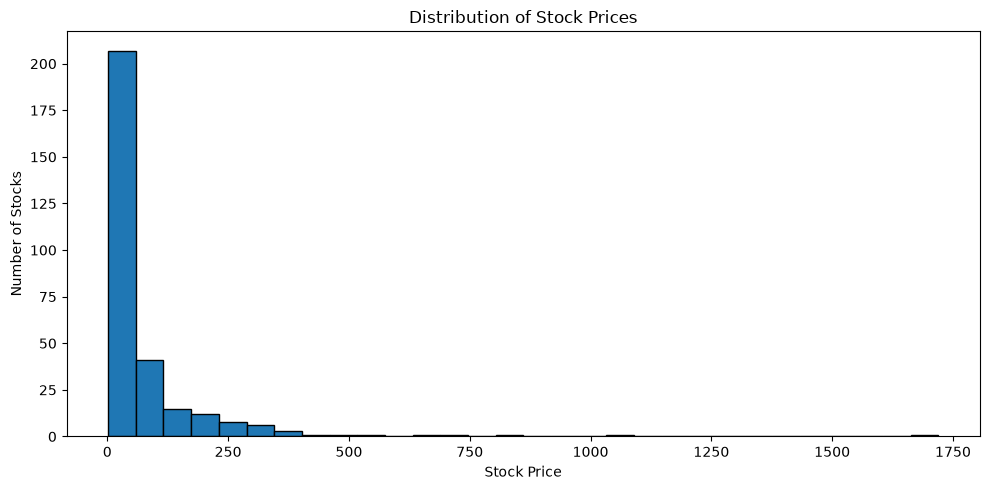

In [76]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["Price"], bins=30, edgecolor="black")

plt.title("Distribution of Stock Prices")
plt.xlabel("Stock Price")
plt.ylabel("Number of Stocks")

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\stock_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [77]:

print(os.getcwd())

C:\Users\DEVI\OneDrive\Regex


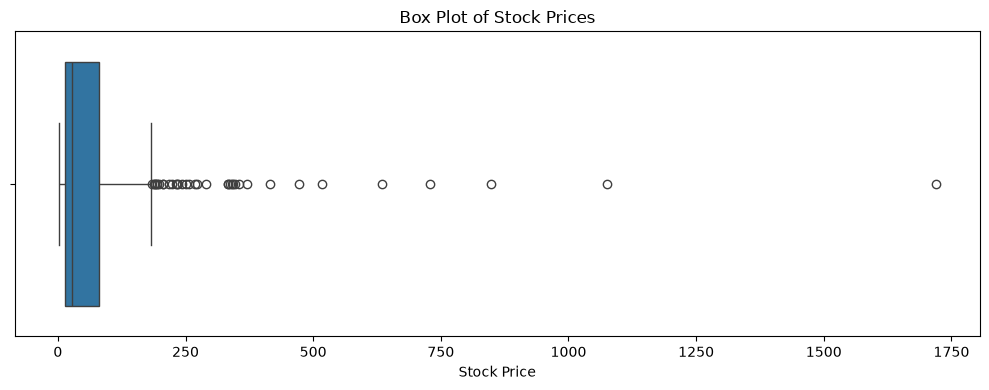

In [78]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Price"])

plt.title("Box Plot of Stock Prices")
plt.xlabel("Stock Price")

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\stock_price_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [79]:

top_10_expensive = df.nlargest(10, "Price")[
    ["Symbols", "Name", "Price", "Change%", "Market_Cap"]
]

display(top_10_expensive)


,Symbols,Name,Price,Change%,Market_Cap
214,SNDK,Sandisk Corporation,1719.99,-3.79,2.518390e+11
52,MU,"Micron Technology, Inc.",1074.89,-2.05,1.214000e+12
120,STX,Seagate Technology Holdings plc,848.99,-10.21,1.930540e+11
125,META,"Meta Platforms, Inc.",728.08,0.30,1.855000e+12
77,AMD,"Advanced Micro Devices, Inc.",633.91,2.95,1.035000e+12
93,MSFT,Microsoft Corporation,517.53,0.92,3.843000e+12
174,TSM,Taiwan Semiconductor Manufacturing Company Lim...,472.78,2.96,2.452000e+12
57,WDC,Western Digital Corporation,415.29,-10.22,1.497290e+11
11,TSLA,"Tesla, Inc.",370.59,4.65,1.464000e+12
59,AVGO,Broadcom Inc.,355.14,3.35,1.695000e+12


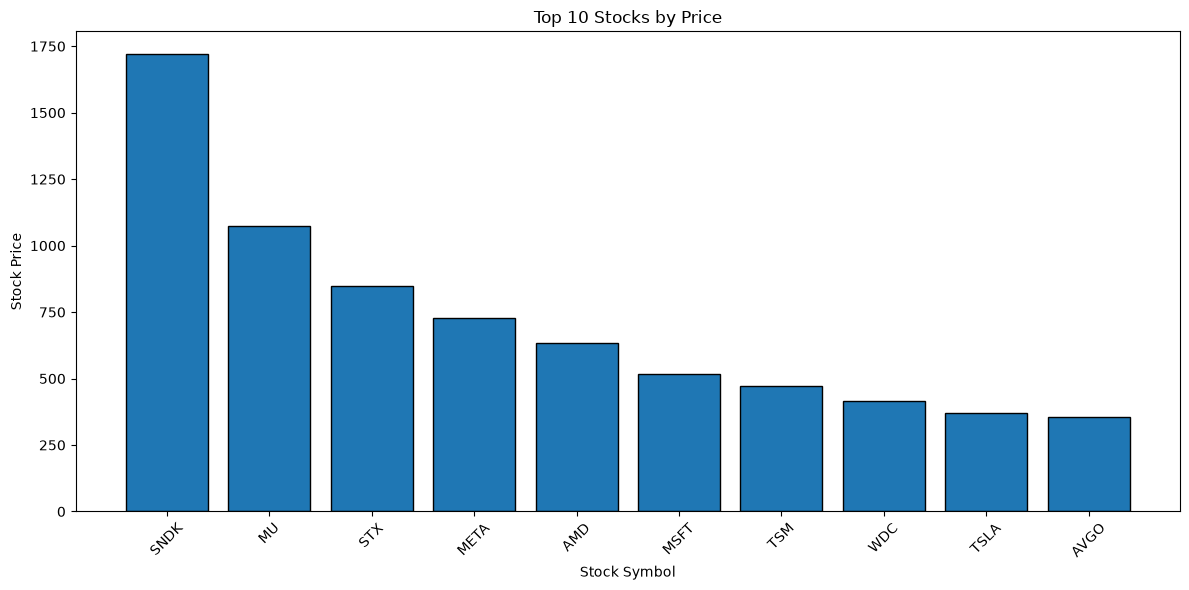

In [80]:

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_expensive["Symbols"],
    top_10_expensive["Price"],
    edgecolor="black"
)

plt.title("Top 10 Stocks by Price")
plt.xlabel("Stock Symbol")
plt.ylabel("Stock Price")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\top_10_stock_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [81]:

top_gainers = df.nlargest(10, "Change%")[
    ["Symbols", "Name", "Price", "Change", "Change%"]
]

top_losers = df.nsmallest(10, "Change%")[
    ["Symbols", "Name", "Price", "Change", "Change%"]
]

print("TOP 10 DAILY GAINERS")
display(top_gainers)

print("TOP 10 DAILY LOSERS")
display(top_losers)


TOP 10 DAILY GAINERS


,Symbols,Name,Price,Change,Change%
240,SYNA,Synaptics Incorporated,121.10,14.95,14.08
181,VSH,"Vishay Intertechnology, Inc.",38.18,3.91,11.41
37,IBRX,"ImmunityBio, Inc.",10.28,1.01,10.83
111,PL,Planet Labs PBC,17.50,1.36,8.43
199,FPS,"Forgent Power Solutions, Inc.",40.35,3.02,8.09
152,AAOI,"Applied Optoelectronics, Inc.",115.59,8.27,7.71
270,JBS,JBS N.V.,11.67,0.81,7.46
46,HPE,Hewlett Packard Enterprise Company,69.33,4.75,7.36
2,SPCX,Space Exploration Technologies Corp.,158.96,10.89,7.35
104,STM,STMicroelectronics N.V.,57.26,3.76,7.03


TOP 10 DAILY LOSERS


,Symbols,Name,Price,Change,Change%
57,WDC,Western Digital Corporation,415.29,-47.27,-10.22
120,STX,Seagate Technology Holdings plc,848.99,-96.58,-10.21
171,ACN,Accenture plc,198.90,-13.40,-6.31
18,STLA,Stellantis N.V.,4.40,-0.29,-6.18
4,CTVA,Vylor Inc.,11.92,-0.65,-5.17
74,QBTS,D-Wave Quantum Inc.,15.77,-0.79,-4.77
191,APP,AppLovin Corporation,268.22,-13.09,-4.65
92,DKNG,DraftKings Inc.,18.59,-0.76,-3.93
259,CTSH,Cognizant Technology Solutions Corporation,58.51,-2.37,-3.89
214,SNDK,Sandisk Corporation,1719.99,-67.70,-3.79


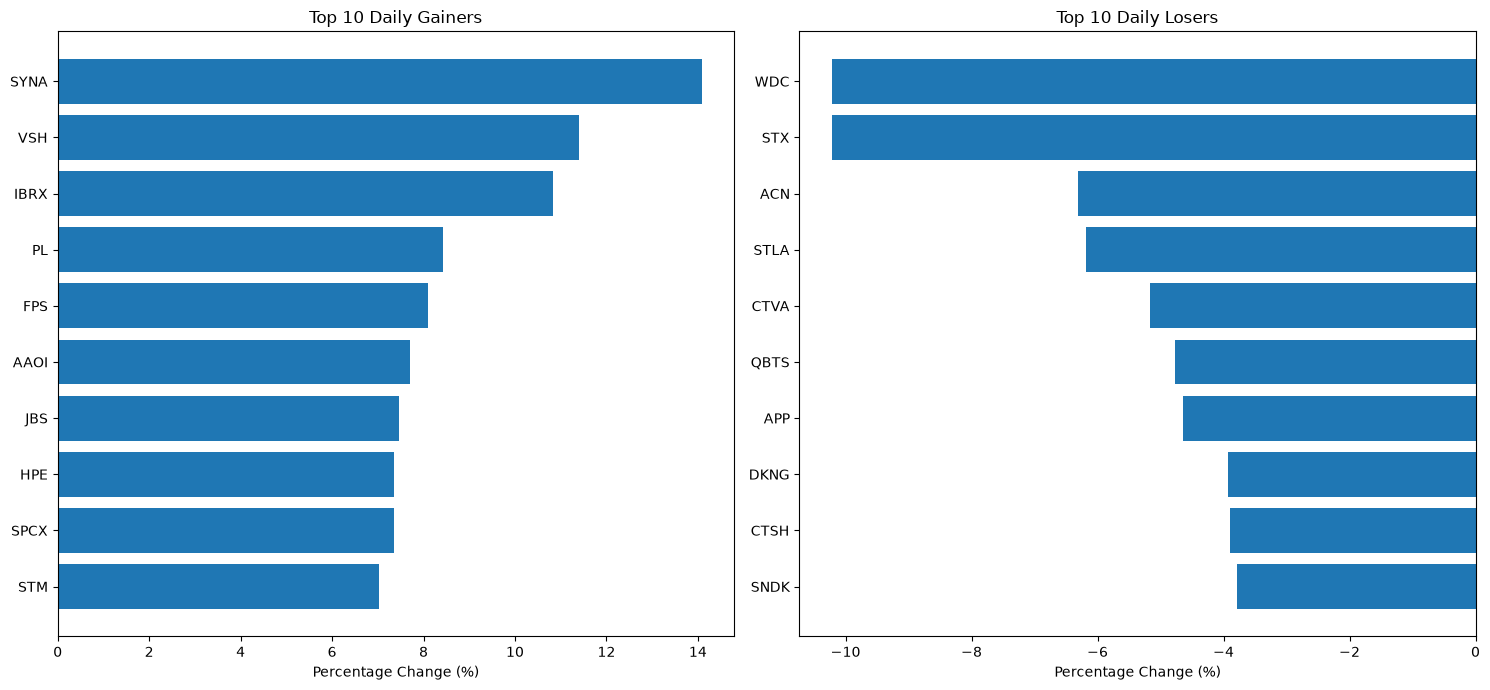

In [82]:

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Top 10 daily gainers
axes[0].barh(top_gainers["Symbols"], top_gainers["Change%"])
axes[0].set_title("Top 10 Daily Gainers")
axes[0].set_xlabel("Percentage Change (%)")
axes[0].invert_yaxis()

# Top 10 daily losers
axes[1].barh(top_losers["Symbols"], top_losers["Change%"])
axes[1].set_title("Top 10 Daily Losers")
axes[1].set_xlabel("Percentage Change (%)")
axes[1].invert_yaxis()

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\top_gainers_losers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [83]:

top_10_volume = df.nlargest(10, "Volume")[
    ["Symbols", "Name", "Price", "Change%", "Volume", "Avg_Vol"]
]

display(top_10_volume)


,Symbols,Name,Price,Change%,Volume,Avg_Vol
0,NKE,"NIKE, Inc.",33.87,-3.64,142717000.0,29461000.0
1,NVDA,NVIDIA Corporation,233.95,1.34,135168000.0,122619000.0
2,SPCX,Space Exploration Technologies Corp.,158.96,7.35,119859000.0,92795000.0
3,INTC,Intel Corporation,119.33,-0.56,95401000.0,107791000.0
4,CTVA,Vylor Inc.,11.92,-5.17,78829000.0,6942000.0
5,NU,Nu Holdings Ltd.,13.43,1.05,78030000.0,82963000.0
6,NOK,Nokia Oyj,10.60,2.22,75816000.0,83736000.0
7,AAL,American Airlines Group Inc.,12.94,-1.45,73233000.0,81233000.0
8,GRAB,Grab Holdings Limited,3.08,-1.28,64559000.0,53398000.0
9,RIVN,"Rivian Automotive, Inc.",14.30,-3.12,60862000.0,27801000.0


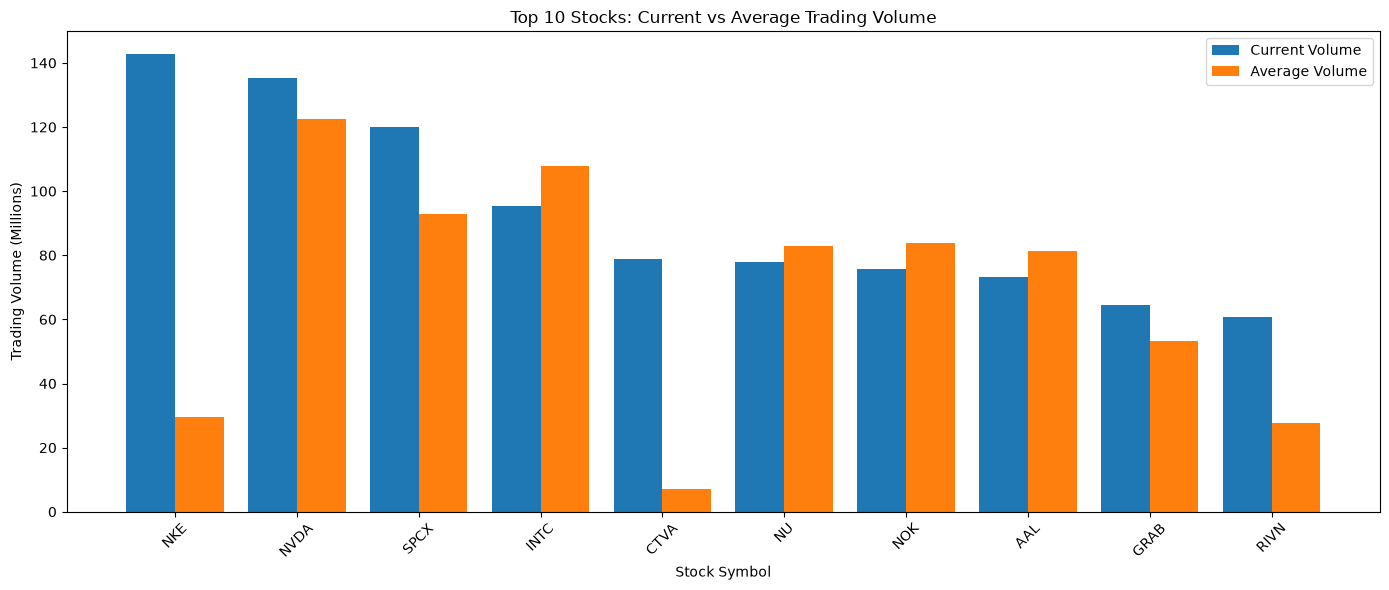

In [84]:

import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(top_10_volume))
width = 0.4

plt.figure(figsize=(14, 6))

plt.bar(
    x - width / 2,
    top_10_volume["Volume"] / 1e6,
    width,
    label="Current Volume"
)

plt.bar(
    x + width / 2,
    top_10_volume["Avg_Vol"] / 1e6,
    width,
    label="Average Volume"
)

plt.title("Top 10 Stocks: Current vs Average Trading Volume")
plt.xlabel("Stock Symbol")
plt.ylabel("Trading Volume (Millions)")
plt.xticks(x, top_10_volume["Symbols"], rotation=45)
plt.legend()

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\top_10_trading_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [85]:

top_10_market_cap = df.nlargest(10, "Market_Cap")[
    ["Symbols", "Name", "Price", "Market_Cap", "Volume", "Change%"]
]

display(top_10_market_cap)


,Symbols,Name,Price,Market_Cap,Volume,Change%
1,NVDA,NVIDIA Corporation,233.95,5.649000e+12,135168000.0,1.34
35,AAPL,Apple Inc.,333.69,4.870000e+12,33279000.0,1.02
62,GOOGL,Alphabet Inc.,343.50,4.201000e+12,23772000.0,1.56
96,GOOG,Alphabet Inc.,340.35,4.162000e+12,17498000.0,1.62
93,MSFT,Microsoft Corporation,517.53,3.843000e+12,17822000.0,0.92
33,AMZN,"Amazon.com, Inc.",251.52,2.713000e+12,33433000.0,1.33
174,TSM,Taiwan Semiconductor Manufacturing Company Lim...,472.78,2.452000e+12,9931000.0,2.96
2,SPCX,Space Exploration Technologies Corp.,158.96,2.094000e+12,119859000.0,7.35
125,META,"Meta Platforms, Inc.",728.08,1.855000e+12,12964000.0,0.30
59,AVGO,Broadcom Inc.,355.14,1.695000e+12,24640000.0,3.35


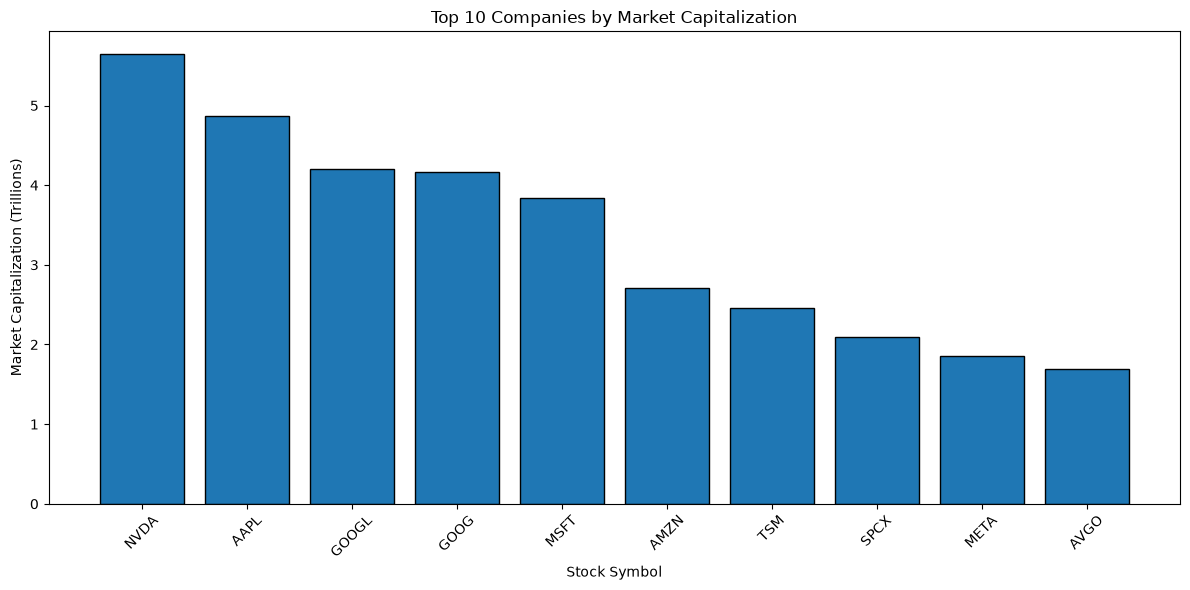

In [86]:

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_market_cap["Symbols"],
    top_10_market_cap["Market_Cap"] / 1e12,
    edgecolor="black"
)

plt.title("Top 10 Companies by Market Capitalization")
plt.xlabel("Stock Symbol")
plt.ylabel("Market Capitalization (Trillions)")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\top_10_market_cap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [87]:

top_10_pe = df.nlargest(10, "PE_Ratio")[
    ["Symbols", "Name", "Price", "PE_Ratio", "Market_Cap"]
]

display(top_10_pe)


,Symbols,Name,Price,PE_Ratio,Market_Cap
137,NBIS,Nebius Group N.V.,242.81,1478.18,6.164900e+10
251,AXTI,"AXT, Inc.",85.87,1198.18,5.631000e+09
11,TSLA,"Tesla, Inc.",370.59,343.28,1.464000e+12
126,BE,Bloom Energy Corporation,289.15,325.87,8.516300e+10
181,VSH,"Vishay Intertechnology, Inc.",38.18,184.01,5.856000e+09
77,AMD,"Advanced Micro Devices, Inc.",633.91,161.80,1.035000e+12
91,PLTR,Palantir Technologies Inc.,188.75,161.43,4.535770e+11
204,PINS,"Pinterest, Inc.",19.26,147.37,1.078900e+10
199,FPS,"Forgent Power Solutions, Inc.",40.35,134.75,1.107700e+10
228,MCHP,Microchip Technology Incorporated,81.32,119.86,4.415700e+10


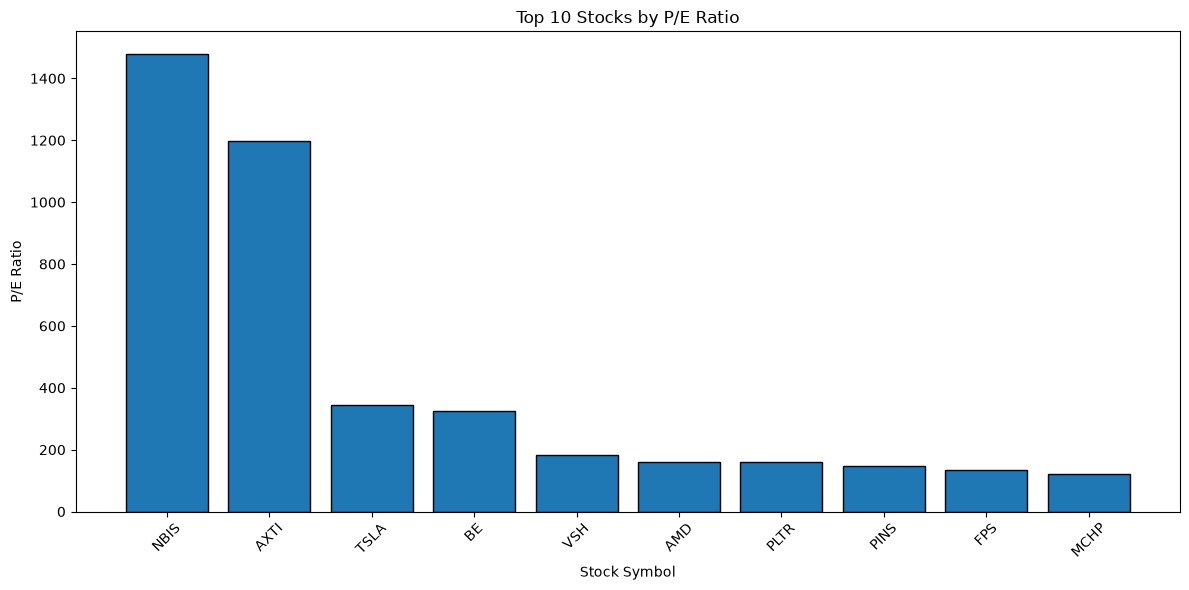

In [88]:

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_pe["Symbols"],
    top_10_pe["PE_Ratio"],
    edgecolor="black"
)

plt.title("Top 10 Stocks by P/E Ratio")
plt.xlabel("Stock Symbol")
plt.ylabel("P/E Ratio")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    r"C:\Users\DEVI\OneDrive\Desktop\Regex\top_10_pe_ratios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [89]:

top_10_52week_gainers = df.nlargest(10, "52Week_Percent")[
    ["Symbols", "Name", "Price", "52Week_Percent", "52Week_Low", "52Week_High"]
]

top_10_52week_losers = df.nsmallest(10, "52Week_Percent")[
    ["Symbols", "Name", "Price", "52Week_Percent", "52Week_Low", "52Week_High"]
]

print("TOP 10 STOCKS BY 52-WEEK PERFORMANCE")
display(top_10_52week_gainers)

print("BOTTOM 10 STOCKS BY 52-WEEK PERFORMANCE")
display(top_10_52week_losers)


TOP 10 STOCKS BY 52-WEEK PERFORMANCE


,Symbols,Name,Price,52Week_Percent,52Week_Low,52Week_High
251,AXTI,"AXT, Inc.",85.87,1490.19,4.00,143.16
214,SNDK,Sandisk Corporation,1719.99,1319.48,115.68,2354.39
162,MRNA,"Moderna, Inc.",190.01,589.94,22.28,208.90
143,IOVA,"Iovance Biotherapeutics, Inc.",14.22,543.44,1.76,15.30
52,MU,"Micron Technology, Inc.",1074.89,462.89,179.61,1255.00
218,ASX,"ASE Technology Holding Co., Ltd.",47.45,316.59,11.07,47.93
37,IBRX,"ImmunityBio, Inc.",10.28,306.52,1.95,12.43
170,VIAV,Viavi Solutions Inc.,47.10,268.54,12.23,60.43
165,UMC,United Microelectronics Corporation,26.27,257.41,6.97,28.96
120,STX,Seagate Technology Holdings plc,848.99,249.62,209.00,1145.00


BOTTOM 10 STOCKS BY 52-WEEK PERFORMANCE


,Symbols,Name,Price,52Week_Percent,52Week_Low,52Week_High
134,FRMI,Fermi Inc.,4.03,-84.71,3.92,32.39
55,SMR,NuScale Power Corporation,7.75,-81.52,7.21,57.42
4,CTVA,Vylor Inc.,11.92,-81.46,11.84,90.97
67,TTD,"The Trade Desk, Inc.",11.95,-77.51,11.77,56.39
178,OKLO,Oklo Inc.,35.87,-74.11,34.38,193.84
41,OPEN,Opendoor Technologies Inc.,2.44,-73.71,2.25,9.69
145,QS,QuantumScape Corporation,4.57,-70.93,4.54,19.07
97,JOBY,"Joby Aviation, Inc.",5.95,-69.60,5.85,19.98
63,SOUN,"SoundHound AI, Inc.",5.84,-68.00,5.65,22.17
183,RBLX,Roblox Corporation,44.12,-65.06,33.88,141.95


In [90]:
output_path = r"C:\Users\DEVI\OneDrive\Desktop\Regex\Yahoo_Finance_EDA_Cleaned.csv"

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", output_path)
print("Dataset shape:", df.shape)

Cleaned dataset saved successfully!
File location: C:\Users\DEVI\OneDrive\Desktop\Regex\Yahoo_Finance_EDA_Cleaned.csv
Dataset shape: (300, 14)


In [91]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("Duplicate Stock Symbols:", df["Symbols"].duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (300, 14)

Missing Values:
Symbols               0
Name                  0
Price                 0
Change                0
Change%               0
Volume                0
Avg_Vol               0
Market_Cap            0
PE_Ratio             92
52Week_Percent        0
52Week_Range          0
Snapshot_DateTime     0
52Week_Low            0
52Week_High           0
dtype: int64

Duplicate Rows: 0
Duplicate Stock Symbols: 0

Data Types:
Symbols                         str
Name                            str
Price                       float64
Change                      float64
Change%                     float64
Volume                      float64
Avg_Vol                     float64
Market_Cap                  float64
PE_Ratio                    float64
52Week_Percent              float64
52Week_Range                    str
Snapshot_DateTime    datetime64[us]
52Week_Low                  float64
52Week_High                 float64
dtype: object


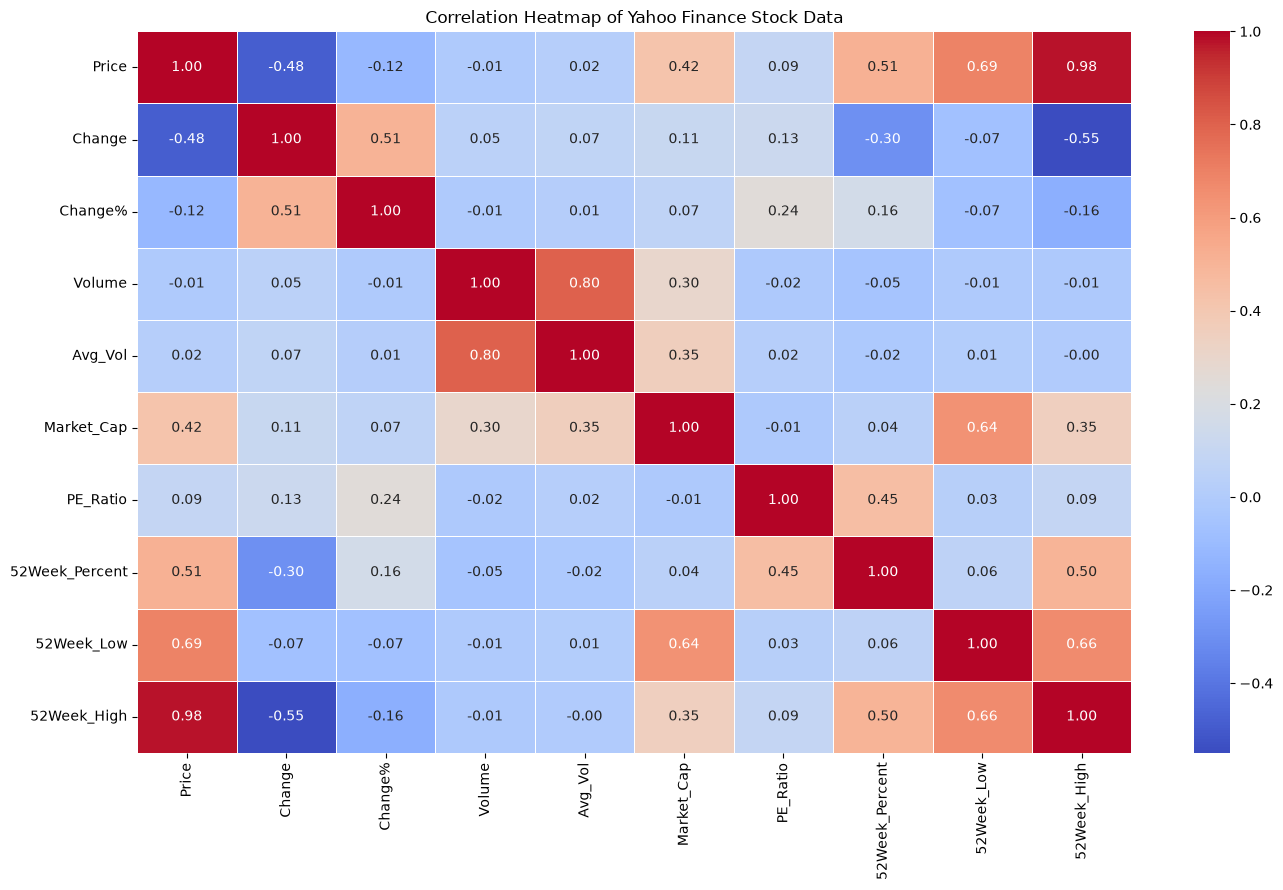

Heatmap saved successfully!
File location: C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Charts\correlation_heatmap.png


In [93]:
image_folder = r"C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Charts"
os.makedirs(image_folder, exist_ok=True)

correlation_matrix = df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Yahoo Finance Stock Data")
plt.tight_layout()

plt.savefig(
    os.path.join(image_folder, "correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Heatmap saved successfully!")
print("File location:", os.path.join(image_folder, "correlation_heatmap.png"))


In [94]:
# Check unusually high or low values in important columns

print("Dataset shape:", df.shape)

print("\nTop 10 highest stock prices:")
print(
    df[["Symbols", "Name", "Price"]]
    .sort_values("Price", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nTop 10 highest market capitalizations:")
print(
    df[["Symbols", "Name", "Market_Cap"]]
    .sort_values("Market_Cap", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nTop 10 highest 52-week percentage values:")
print(
    df[["Symbols", "Name", "52Week_Percent"]]
    .sort_values("52Week_Percent", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nNumeric summary:")
print(df.select_dtypes(include="number").describe().T)

Dataset shape: (300, 14)

Top 10 highest stock prices:
Symbols                                               Name   Price
   SNDK                                Sandisk Corporation 1719.99
     MU                            Micron Technology, Inc. 1074.89
    STX                    Seagate Technology Holdings plc  848.99
   META                               Meta Platforms, Inc.  728.08
    AMD                       Advanced Micro Devices, Inc.  633.91
   MSFT                              Microsoft Corporation  517.53
    TSM Taiwan Semiconductor Manufacturing Company Limited  472.78
    WDC                        Western Digital Corporation  415.29
   TSLA                                        Tesla, Inc.  370.59
   AVGO                                      Broadcom Inc.  355.14

Top 10 highest market capitalizations:
Symbols                                               Name   Market_Cap
   NVDA                                 NVIDIA Corporation 5.649000e+12
   AAPL                 

In [95]:
# Check whether current prices fall within their 52-week ranges

invalid_range = df[
    (df["Price"] < df["52Week_Low"]) |
    (df["Price"] > df["52Week_High"])
]

print("Stocks outside their 52-week range:", len(invalid_range))

print("\nStocks outside the range:")
print(
    invalid_range[
        ["Symbols", "Name", "Price", "52Week_Low", "52Week_High"]
    ].to_string(index=False)
)

print("\nStocks with valid ranges:")
print(
    ((df["Price"] >= df["52Week_Low"]) &
     (df["Price"] <= df["52Week_High"])).sum()
)

Stocks outside their 52-week range: 0

Stocks outside the range:
Empty DataFrame
Columns: [Symbols, Name, Price, 52Week_Low, 52Week_High]
Index: []

Stocks with valid ranges:
300


In [96]:
# Calculate the percentage change from the 52-week low

df["Calculated_52Week_Percent"] = (
    (df["Price"] - df["52Week_Low"])
    / df["52Week_Low"]
) * 100

print(
    df[
        ["Symbols", "Price", "52Week_Low",
         "52Week_Percent", "Calculated_52Week_Percent"]
    ]
    .sort_values("52Week_Percent", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

Symbols   Price  52Week_Low  52Week_Percent  Calculated_52Week_Percent
   AXTI   85.87        4.00         1490.19                    2046.75
   SNDK 1719.99      115.68         1319.48                    1386.85
   MRNA  190.01       22.28          589.94                     752.83
   IOVA   14.22        1.76          543.44                     707.95
     MU 1074.89      179.61          462.89                     498.46
    ASX   47.45       11.07          316.59                     328.64
   IBRX   10.28        1.95          306.52                     427.18
   VIAV   47.10       12.23          268.54                     285.12
    UMC   26.27        6.97          257.41                     276.90
    STX  848.99      209.00          249.62                     306.22


In [97]:
print(
    df[
        [
            "Symbols",
            "Price",
            "52Week_Low",
            "52Week_High",
            "52Week_Percent",
            "52Week_Range"
        ]
    ]
    .sort_values("52Week_Percent", ascending=False)
    .head(10)
    .to_string(index=False)
)

Symbols   Price  52Week_Low  52Week_High  52Week_Percent      52Week_Range
   AXTI   85.87        4.00       143.16         1490.19     4.00 - 143.16
   SNDK 1719.99      115.68      2354.39         1319.48 115.68 - 2,354.39
   MRNA  190.01       22.28       208.90          589.94    22.28 - 208.90
   IOVA   14.22        1.76        15.30          543.44      1.76 - 15.30
     MU 1074.89      179.61      1255.00          462.89 179.61 - 1,255.00
    ASX   47.45       11.07        47.93          316.59     11.07 - 47.93
   IBRX   10.28        1.95        12.43          306.52      1.95 - 12.43
   VIAV   47.10       12.23        60.43          268.54     12.23 - 60.43
    UMC   26.27        6.97        28.96          257.41      6.97 - 28.96
    STX  848.99      209.00      1145.00          249.62 209.00 - 1,145.00


In [98]:
# Inspect the 10 largest market capitalizations

top_market_cap = (
    df[["Symbols", "Name", "Market_Cap"]]
    .sort_values("Market_Cap", ascending=False)
    .head(10)
    .copy()
)

top_market_cap["Market_Cap_Trillions"] = (
    top_market_cap["Market_Cap"] / 1_000_000_000_000
)

print(
    top_market_cap[
        ["Symbols", "Name", "Market_Cap", "Market_Cap_Trillions"]
    ].to_string(index=False)
)

Symbols                                               Name   Market_Cap  Market_Cap_Trillions
   NVDA                                 NVIDIA Corporation 5.649000e+12                 5.649
   AAPL                                         Apple Inc. 4.870000e+12                 4.870
  GOOGL                                      Alphabet Inc. 4.201000e+12                 4.201
   GOOG                                      Alphabet Inc. 4.162000e+12                 4.162
   MSFT                              Microsoft Corporation 3.843000e+12                 3.843
   AMZN                                   Amazon.com, Inc. 2.713000e+12                 2.713
    TSM Taiwan Semiconductor Manufacturing Company Limited 2.452000e+12                 2.452
   SPCX               Space Exploration Technologies Corp. 2.094000e+12                 2.094
   META                               Meta Platforms, Inc. 1.855000e+12                 1.855
   AVGO                                      Broadcom Inc. 1

In [99]:
print("Snapshot date range:")
print("Earliest:", df["Snapshot_DateTime"].min())
print("Latest:", df["Snapshot_DateTime"].max())

print("\nNumber of unique snapshot timestamps:")
print(df["Snapshot_DateTime"].nunique())

print("\nSnapshot timestamp counts:")
print(df["Snapshot_DateTime"].value_counts().head(10))

Snapshot date range:
Earliest: 2026-10-05 17:00:00
Latest: 2026-10-05 17:00:00

Number of unique snapshot timestamps:
1

Snapshot timestamp counts:
Snapshot_DateTime
2026-10-05 17:00:00    300
Name: count, dtype: int64


In [100]:
# Final data quality audit

print("1. Dataset shape:")
print(df.shape)

print("\n2. Missing values:")
print(df.isnull().sum())

print("\n3. Duplicate rows:")
print(df.duplicated().sum())

print("\n4. Duplicate stock symbols:")
print(df["Symbols"].duplicated().sum())

print("\n5. Data types:")
print(df.dtypes)

print("\n6. Invalid percentage values:")
print("Change% outside -100 to 100:",
      ((df["Change%"] < -100) | (df["Change%"] > 100)).sum())

print("\n7. Invalid price values:")
print("Price <= 0:", (df["Price"] <= 0).sum())

print("\n8. Invalid 52-week ranges:")
print("Low > High:", (df["52Week_Low"] > df["52Week_High"]).sum())

1. Dataset shape:
(300, 15)

2. Missing values:
Symbols                       0
Name                          0
Price                         0
Change                        0
Change%                       0
Volume                        0
Avg_Vol                       0
Market_Cap                    0
PE_Ratio                     92
52Week_Percent                0
52Week_Range                  0
Snapshot_DateTime             0
52Week_Low                    0
52Week_High                   0
Calculated_52Week_Percent     0
dtype: int64

3. Duplicate rows:
0

4. Duplicate stock symbols:
0

5. Data types:
Symbols                                 str
Name                                    str
Price                               float64
Change                              float64
Change%                             float64
Volume                              float64
Avg_Vol                             float64
Market_Cap                          float64
PE_Ratio                            fl

In [101]:
# Remove the temporary validation column

df.drop(
    columns=["Calculated_52Week_Percent"],
    inplace=True,
    errors="ignore"
)

print("Updated dataset shape:", df.shape)
print("\nFinal columns:")
print(df.columns.tolist())

Updated dataset shape: (300, 14)

Final columns:
['Symbols', 'Name', 'Price', 'Change', 'Change%', 'Volume', 'Avg_Vol', 'Market_Cap', 'PE_Ratio', '52Week_Percent', '52Week_Range', 'Snapshot_DateTime', '52Week_Low', '52Week_High']


In [102]:
# Summary of daily stock performance

print("Total stocks analyzed:", len(df))

print("\nAverage daily percentage change:")
print(round(df["Change%"].mean(), 2), "%")

print("\nStocks with positive daily changes:")
print((df["Change%"] > 0).sum())

print("\nStocks with negative daily changes:")
print((df["Change%"] < 0).sum())

print("\nStocks with no daily change:")
print((df["Change%"] == 0).sum())

print("\nTop 5 daily gainers:")
print(
    df[["Symbols", "Name", "Change%"]]
    .sort_values("Change%", ascending=False)
    .head(5)
    .to_string(index=False)
)

print("\nTop 5 daily losers:")
print(
    df[["Symbols", "Name", "Change%"]]
    .sort_values("Change%", ascending=True)
    .head(5)
    .to_string(index=False)
)

Total stocks analyzed: 300

Average daily percentage change:
0.69 %

Stocks with positive daily changes:
175

Stocks with negative daily changes:
120

Stocks with no daily change:
5

Top 5 daily gainers:
Symbols                          Name  Change%
   SYNA        Synaptics Incorporated    14.08
    VSH  Vishay Intertechnology, Inc.    11.41
   IBRX             ImmunityBio, Inc.    10.83
     PL               Planet Labs PBC     8.43
    FPS Forgent Power Solutions, Inc.     8.09

Top 5 daily losers:
Symbols                            Name  Change%
    WDC     Western Digital Corporation   -10.22
    STX Seagate Technology Holdings plc   -10.21
    ACN                   Accenture plc    -6.31
   STLA                 Stellantis N.V.    -6.18
   CTVA                      Vylor Inc.    -5.17


In [103]:
# Analyze current volume versus average trading volume

df["Volume_Ratio"] = df["Volume"] / df["Avg_Vol"]

print("Top 10 stocks by current trading volume:")
print(
    df[["Symbols", "Name", "Volume", "Avg_Vol", "Volume_Ratio"]]
    .sort_values("Volume", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

print("\nTop 10 stocks trading furthest above average volume:")
print(
    df[["Symbols", "Name", "Volume", "Avg_Vol", "Volume_Ratio"]]
    .sort_values("Volume_Ratio", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

Top 10 stocks by current trading volume:
Symbols                                 Name      Volume     Avg_Vol  Volume_Ratio
    NKE                           NIKE, Inc. 142717000.0  29461000.0          4.84
   NVDA                   NVIDIA Corporation 135168000.0 122619000.0          1.10
   SPCX Space Exploration Technologies Corp. 119859000.0  92795000.0          1.29
   INTC                    Intel Corporation  95401000.0 107791000.0          0.89
   CTVA                           Vylor Inc.  78829000.0   6942000.0         11.36
     NU                     Nu Holdings Ltd.  78030000.0  82963000.0          0.94
    NOK                            Nokia Oyj  75816000.0  83736000.0          0.91
    AAL         American Airlines Group Inc.  73233000.0  81233000.0          0.90
   GRAB                Grab Holdings Limited  64559000.0  53398000.0          1.21
   RIVN              Rivian Automotive, Inc.  60862000.0  27801000.0          2.19

Top 10 stocks trading furthest above average 

In [104]:
# Analyze stock prices

print("Average stock price:", round(df["Price"].mean(), 2))
print("Median stock price:", round(df["Price"].median(), 2))
print("Highest stock price:", round(df["Price"].max(), 2))
print("Lowest stock price:", round(df["Price"].min(), 2))

print("\nTop 10 highest-priced stocks:")
print(
    df[["Symbols", "Name", "Price"]]
    .sort_values("Price", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nTop 10 lowest-priced stocks:")
print(
    df[["Symbols", "Name", "Price"]]
    .sort_values("Price", ascending=True)
    .head(10)
    .to_string(index=False)
)

Average stock price: 79.63
Median stock price: 28.3
Highest stock price: 1719.99
Lowest stock price: 1.72

Top 10 highest-priced stocks:
Symbols                                               Name   Price
   SNDK                                Sandisk Corporation 1719.99
     MU                            Micron Technology, Inc. 1074.89
    STX                    Seagate Technology Holdings plc  848.99
   META                               Meta Platforms, Inc.  728.08
    AMD                       Advanced Micro Devices, Inc.  633.91
   MSFT                              Microsoft Corporation  517.53
    TSM Taiwan Semiconductor Manufacturing Company Limited  472.78
    WDC                        Western Digital Corporation  415.29
   TSLA                                        Tesla, Inc.  370.59
   AVGO                                      Broadcom Inc.  355.14

Top 10 lowest-priced stocks:
Symbols                             Name  Price
    WIT                    Wipro Limited   1.72


In [105]:
# Analyze market capitalization

print("Average market capitalization:")
print(round(df["Market_Cap"].mean() / 1e9, 2), "billion")

print("\nMedian market capitalization:")
print(round(df["Market_Cap"].median() / 1e9, 2), "billion")

print("\nTop 10 companies by market capitalization:")
print(
    df[["Symbols", "Name", "Market_Cap"]]
    .sort_values("Market_Cap", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nBottom 10 companies by market capitalization:")
print(
    df[["Symbols", "Name", "Market_Cap"]]
    .sort_values("Market_Cap", ascending=True)
    .head(10)
    .to_string(index=False)
)

Average market capitalization:
197.21 billion

Median market capitalization:
25.08 billion

Top 10 companies by market capitalization:
Symbols                                               Name   Market_Cap
   NVDA                                 NVIDIA Corporation 5.649000e+12
   AAPL                                         Apple Inc. 4.870000e+12
  GOOGL                                      Alphabet Inc. 4.201000e+12
   GOOG                                      Alphabet Inc. 4.162000e+12
   MSFT                              Microsoft Corporation 3.843000e+12
   AMZN                                   Amazon.com, Inc. 2.713000e+12
    TSM Taiwan Semiconductor Manufacturing Company Limited 2.452000e+12
   SPCX               Space Exploration Technologies Corp. 2.094000e+12
   META                               Meta Platforms, Inc. 1.855000e+12
   AVGO                                      Broadcom Inc. 1.695000e+12

Bottom 10 companies by market capitalization:
Symbols                   

In [106]:
# Analyze P/E ratios

pe_df = df.dropna(subset=["PE_Ratio"])

print("Stocks with available P/E ratios:", len(pe_df))
print("Stocks with missing P/E ratios:", df["PE_Ratio"].isna().sum())

print("\nAverage P/E ratio:", round(pe_df["PE_Ratio"].mean(), 2))
print("Median P/E ratio:", round(pe_df["PE_Ratio"].median(), 2))
print("Lowest P/E ratio:", round(pe_df["PE_Ratio"].min(), 2))
print("Highest P/E ratio:", round(pe_df["PE_Ratio"].max(), 2))

print("\nTop 10 stocks by P/E ratio:")
print(
    pe_df[["Symbols", "Name", "PE_Ratio"]]
    .sort_values("PE_Ratio", ascending=False)
    .head(10)
    .to_string(index=False)
)

Stocks with available P/E ratios: 208
Stocks with missing P/E ratios: 92

Average P/E ratio: 46.25
Median P/E ratio: 20.43
Lowest P/E ratio: 2.14
Highest P/E ratio: 1478.18

Top 10 stocks by P/E ratio:
Symbols                              Name  PE_Ratio
   NBIS                 Nebius Group N.V.   1478.18
   AXTI                         AXT, Inc.   1198.18
   TSLA                       Tesla, Inc.    343.28
     BE          Bloom Energy Corporation    325.87
    VSH      Vishay Intertechnology, Inc.    184.01
    AMD      Advanced Micro Devices, Inc.    161.80
   PLTR        Palantir Technologies Inc.    161.43
   PINS                   Pinterest, Inc.    147.37
    FPS     Forgent Power Solutions, Inc.    134.75
   MCHP Microchip Technology Incorporated    119.86


In [107]:

# Analyze correlations between numeric columns

correlation_matrix = df.select_dtypes(include="number").corr()

print("Correlation with Stock Price:")
print(
    correlation_matrix["Price"]
    .sort_values(ascending=False)
    .round(2)
)

print("\nStrong correlations (absolute correlation >= 0.50):")

for col in correlation_matrix.columns:
    for other_col in correlation_matrix.columns:
        if col < other_col:
            value = correlation_matrix.loc[col, other_col]
            if abs(value) >= 0.50:
                print(f"{col} and {other_col}: {value:.2f}")


Correlation with Stock Price:
Price             1.00
52Week_High       0.98
52Week_Low        0.69
52Week_Percent    0.51
Market_Cap        0.42
PE_Ratio          0.09
Avg_Vol           0.02
Volume           -0.01
Volume_Ratio     -0.02
Change%          -0.12
Change           -0.48
Name: Price, dtype: float64

Strong correlations (absolute correlation >= 0.50):
Change and Change%: 0.51
Avg_Vol and Volume: 0.80
52Week_Percent and Price: 0.51
52Week_Low and Price: 0.69
52Week_Low and Market_Cap: 0.64
52Week_High and Price: 0.98
52Week_High and Change: -0.55
52Week_High and 52Week_Percent: 0.50
52Week_High and 52Week_Low: 0.66


In [108]:

# Remove the temporary analysis column
df.drop(columns=["Volume_Ratio"], inplace=True, errors="ignore")

# Check the final dataset structure
print("Final dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate stock symbols:", df["Symbols"].duplicated().sum())


Final dataset shape: (300, 14)

Column names:
['Symbols', 'Name', 'Price', 'Change', 'Change%', 'Volume', 'Avg_Vol', 'Market_Cap', 'PE_Ratio', '52Week_Percent', '52Week_Range', 'Snapshot_DateTime', '52Week_Low', '52Week_High']

Missing values:
Symbols               0
Name                  0
Price                 0
Change                0
Change%               0
Volume                0
Avg_Vol               0
Market_Cap            0
PE_Ratio             92
52Week_Percent        0
52Week_Range          0
Snapshot_DateTime     0
52Week_Low            0
52Week_High           0
dtype: int64

Duplicate rows: 0
Duplicate stock symbols: 0


In [109]:
# Main project folder
project_folder = r"C:\Users\DEVI\OneDrive\Desktop\Regex"

# Folder to store EDA charts
image_folder = os.path.join(project_folder, "EDA_Charts")
os.makedirs(image_folder, exist_ok=True)

# Save the final cleaned dataset
csv_path = os.path.join(project_folder, "Yahoo_Finance_EDA_Cleaned.csv")
df.to_csv(csv_path, index=False)

print("Final dataset saved successfully!")
print("CSV location:", csv_path)
print("Dataset shape:", df.shape)
print("Charts folder:", image_folder)


Final dataset saved successfully!
CSV location: C:\Users\DEVI\OneDrive\Desktop\Regex\Yahoo_Finance_EDA_Cleaned.csv
Dataset shape: (300, 14)
Charts folder: C:\Users\DEVI\OneDrive\Desktop\Regex\EDA_Charts


In [111]:

# Final Yahoo Finance EDA summary

print("=" * 50)
print("YAHOO FINANCE STOCK MARKET EDA SUMMARY")
print("=" * 50)

print("\n1. DATASET OVERVIEW")
print("Total stock records:", len(df))
print("Total columns:", len(df.columns))
print("Unique stocks:", df["Symbols"].nunique())
print("Snapshot date:", df["Snapshot_DateTime"].min())

print("\n2. STOCK PRICE ANALYSIS")
print("Average price:", round(df["Price"].mean(), 2))
print("Median price:", round(df["Price"].median(), 2))
print("Highest-priced stock:",
      df.loc[df["Price"].idxmax(), "Symbols"],
      "-", df["Price"].max())
print("Lowest-priced stock:",
      df.loc[df["Price"].idxmin(), "Symbols"],
      "-", df["Price"].min())

print("\n3. DAILY MARKET PERFORMANCE")
print("Average daily change (%):", round(df["Change%"].mean(), 2))
print("Stocks with positive change:", (df["Change%"] > 0).sum())
print("Stocks with negative change:", (df["Change%"] < 0).sum())
print("Stocks with no change:", (df["Change%"] == 0).sum())

print("\n4. DATA QUALITY")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate symbols:", df["Symbols"].duplicated().sum())
print("Missing P/E ratios:", df["PE_Ratio"].isna().sum())

print("\n5. HIGHEST TRADING VOLUME")
print(
    df.nlargest(5, "Volume")[["Symbols", "Name", "Volume"]]
    .to_string(index=False)
)


YAHOO FINANCE STOCK MARKET EDA SUMMARY

1. DATASET OVERVIEW
Total stock records: 300
Total columns: 14
Unique stocks: 300
Snapshot date: 2026-10-05 17:00:00

2. STOCK PRICE ANALYSIS
Average price: 79.63
Median price: 28.3
Highest-priced stock: SNDK - 1719.99
Lowest-priced stock: WIT - 1.72

3. DAILY MARKET PERFORMANCE
Average daily change (%): 0.69
Stocks with positive change: 175
Stocks with negative change: 120
Stocks with no change: 5

4. DATA QUALITY
Duplicate rows: 0
Duplicate symbols: 0
Missing P/E ratios: 92

5. HIGHEST TRADING VOLUME
Symbols                                 Name      Volume
    NKE                           NIKE, Inc. 142717000.0
   NVDA                   NVIDIA Corporation 135168000.0
   SPCX Space Exploration Technologies Corp. 119859000.0
   INTC                    Intel Corporation  95401000.0
   CTVA                           Vylor Inc.  78829000.0


## Business Insights

1. **Overall market performance:** Of the 300 stocks analyzed, 175 recorded positive daily percentage changes, 120 recorded negative changes, and 5 remained unchanged. The average daily percentage change was approximately **+0.69%** for this selected group of stocks.

2. **Stock price distribution:** The average stock price was **$79.63**, while the median was **$28.30**. The average being higher than the median suggests a right-skewed distribution, where a small number of high-priced stocks influence the average.

3. **Highest and lowest stock prices:** SNDK had the highest recorded price at **$1,719.99**, while WIT had the lowest at **$1.72** in the collected dataset. These values should be verified against the source before final presentation.

4. **Trading activity:** NKE and NVDA had the highest recorded trading volumes, at approximately **142.72 million** and **135.17 million** shares, respectively. High trading volume indicates substantial trading activity, but does not by itself establish whether a stock is a good investment.

5. **P/E ratio analysis:** Of the 300 stocks, 208 had available P/E ratios and 92 had missing values. The median P/E ratio was **20.43**, compared with an average of **46.25**, indicating that a small number of high P/E values increased the average.

6. **Correlation analysis:** Stock price and 52-week high had a strong positive correlation of **0.98**. Current volume and average volume had a positive correlation of **0.80**. Correlation indicates association, not causation.

7. **Data quality:** The final dataset contained **300 unique stock symbols**, no duplicate rows, and no duplicate symbols. However, missing P/E values and suspicious ticker/company mappings require source verification.

## Conclusion

This project demonstrates how web scraping, data cleaning, exploratory data analysis, and visualization can be used to examine stock prices, daily changes, trading volumes, market capitalization, P/E ratios, and 52-week trading ranges. The analysis identifies patterns and potential areas for further investigation. Since the dataset represents a single snapshot collected on October 5, 2026, it should not be used to infer long-term trends or make investment decisions. Validating scraped values against the source is an important final step before presenting the findings.